In [1]:
# ============================================================
# 06_BUSINESS_ANALYSIS
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project directories
project_dir = os.getcwd()

enrich_dir = os.path.join(
    project_dir,
    "05_Enriched_Data"
)

analysis_dir = os.path.join(
    project_dir,
    "06_Analysis"
)

os.makedirs(analysis_dir, exist_ok=True)

print("Project directory:", project_dir)
print("Enriched data directory:", enrich_dir)
print("Analysis directory:", analysis_dir)

Project directory: C:\Users\Sai\Desktop\New folder
Enriched data directory: C:\Users\Sai\Desktop\New folder\05_Enriched_Data
Analysis directory: C:\Users\Sai\Desktop\New folder\06_Analysis


In [2]:
# ============================================================
# LOAD FINAL ENRICHED DATA
# ============================================================

enrichment_file = os.path.join(
    enrich_dir,
    "NexziByte_B2B_Lead_Intelligence_Enriched_V2.csv"
)

business_df = pd.read_csv(
    enrichment_file
)

print("=" * 60)
print("BUSINESS ANALYSIS DATA LOADED")
print("=" * 60)

print("Rows:", len(business_df))
print("Columns:", len(business_df.columns))

print("\nColumns:")
print(business_df.columns.tolist())

BUSINESS ANALYSIS DATA LOADED
Rows: 313
Columns: 31

Columns:
['Company Name', 'Technology Areas Cleaned', 'AI/ML Signals', 'API/Platform Signals', 'Cloud/Data Signals', 'Software Development Signals', 'AI Technology Evidence', 'Cloud/Data Technology Evidence', 'API/Platform Technology Evidence', 'Software Development Evidence', 'AI Evidence Count', 'Cloud/Data Evidence Count', 'API/Platform Evidence Count', 'Software Development Evidence Count', 'Total Technology Evidence', 'High Value AI Terms', 'High Value Cloud Terms', 'High Value Platform Terms', 'High Value Dev Terms', 'High Value Technology Count', 'Technology Fit Score V2', 'Company Fit Score', 'Growth Intent Score', 'Funding Expansion Score', 'Marketing Readiness Score', 'Data Confidence Score', 'Marketing Readiness V2', 'Data Quality Status V2', 'Prospect Score V2', 'Lead Priority V2', 'Prospect Rank V2']


In [3]:
# ============================================================
# 2. EXECUTIVE KPI ANALYSIS
# ============================================================

executive_kpi = pd.DataFrame({
    "KPI": [
        "Total Companies",
        "Tier 1 High Priority Leads",
        "Tier 2 Priority Leads",
        "Tier 3 Nurture Leads",
        "Tier 4 Low Priority Leads",
        "Average Prospect Score",
        "Average Technology Fit Score",
        "Average Company Fit Score",
        "Average Growth Intent Score",
        "Average Funding Expansion Score",
        "Average Marketing Readiness Score",
        "Average Data Confidence Score"
    ],
    "Value": [
        len(business_df),

        (
            business_df["Lead Priority V2"]
            == "Tier 1 - High Priority"
        ).sum(),

        (
            business_df["Lead Priority V2"]
            == "Tier 2 - Priority"
        ).sum(),

        (
            business_df["Lead Priority V2"]
            == "Tier 3 - Nurture"
        ).sum(),

        (
            business_df["Lead Priority V2"]
            == "Tier 4 - Low Priority"
        ).sum(),

        round(business_df["Prospect Score V2"].mean(), 2),
        round(business_df["Technology Fit Score V2"].mean(), 2),
        round(business_df["Company Fit Score"].mean(), 2),
        round(business_df["Growth Intent Score"].mean(), 2),
        round(business_df["Funding Expansion Score"].mean(), 2),
        round(business_df["Marketing Readiness Score"].mean(), 2),
        round(business_df["Data Confidence Score"].mean(), 2)
    ]
})

display(executive_kpi)

,KPI,Value
0,Total Companies,313.00
1,Tier 1 High Priority Leads,40.00
2,Tier 2 Priority Leads,86.00
3,Tier 3 Nurture Leads,100.00
4,Tier 4 Low Priority Leads,87.00
5,Average Prospect Score,62.83
6,Average Technology Fit Score,18.49
7,Average Company Fit Score,12.36
8,Average Growth Intent Score,10.03
9,Average Funding Expansion Score,5.34


In [4]:
# ============================================================
# KPI VALIDATION
# ============================================================

assert len(business_df) == 313

assert (
    business_df["Lead Priority V2"]
    .value_counts()
    .get("Tier 1 - High Priority", 0)
) == 40

assert (
    business_df["Lead Priority V2"]
    .value_counts()
    .get("Tier 2 - Priority", 0)
) == 86

assert (
    business_df["Lead Priority V2"]
    .value_counts()
    .get("Tier 3 - Nurture", 0)
) == 100

assert (
    business_df["Lead Priority V2"]
    .value_counts()
    .get("Tier 4 - Low Priority", 0)
) == 87

print("Executive KPI validation: PASSED")

Executive KPI validation: PASSED


In [5]:
# ============================================================
# EXPORT EXECUTIVE KPI
# ============================================================

executive_kpi.to_csv(
    os.path.join(
        analysis_dir,
        "Executive_KPI_Summary.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

print(
    "Created:",
    os.path.join(
        analysis_dir,
        "Executive_KPI_Summary.csv"
    )
)

Created: C:\Users\Sai\Desktop\New folder\06_Analysis\Executive_KPI_Summary.csv


In [6]:
# ============================================================
# PROSPECT SCORE DISTRIBUTION
# ============================================================

prospect_distribution = (
    business_df["Prospect Score V2"]
    .value_counts()
    .sort_index()
    .rename_axis("Prospect Score")
    .reset_index(name="Company Count")
)

prospect_distribution["Percentage"] = (
    prospect_distribution["Company Count"]
    / len(business_df)
    * 100
).round(2)

display(prospect_distribution.head(20))

prospect_distribution.to_csv(
    os.path.join(
        analysis_dir,
        "Prospect_Score_Distribution.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

,Prospect Score,Company Count,Percentage
0,6,6,1.92
1,8,3,0.96
2,12,3,0.96
3,15,1,0.32
4,16,6,1.92
5,18,3,0.96
6,20,3,0.96
7,21,2,0.64
8,22,10,3.19
9,23,1,0.32


In [7]:
# ============================================================
# LEAD PRIORITY DISTRIBUTION
# ============================================================

lead_priority_analysis = (
    business_df["Lead Priority V2"]
    .value_counts()
    .rename_axis("Lead Priority")
    .reset_index(name="Company Count")
)

lead_priority_analysis["Percentage"] = (
    lead_priority_analysis["Company Count"]
    / len(business_df)
    * 100
).round(2)

display(lead_priority_analysis)

lead_priority_analysis.to_csv(
    os.path.join(
        analysis_dir,
        "Lead_Priority_Analysis.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

,Lead Priority,Company Count,Percentage
0,Tier 3 - Nurture,100,31.95
1,Tier 4 - Low Priority,87,27.80
2,Tier 2 - Priority,86,27.48
3,Tier 1 - High Priority,40,12.78


In [9]:
# ============================================================
# LOAD FULL FINAL DATASET FOR BUSINESS ANALYSIS
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

possible_files = [
    os.path.join(
        "05_Final_Output",
        "NexziByte_B2B_Lead_Intelligence_FINAL.csv"
    ),
    os.path.join(
        "04_Clean_Data",
        "NexziByte_B2B_Lead_Intelligence_FINAL.csv"
    ),
    "NexziByte_B2B_Lead_Intelligence_FINAL.csv"
]

final_file = None

for file in possible_files:
    if os.path.exists(file):
        final_file = file
        break

if final_file is None:
    raise FileNotFoundError(
        "Final 313-row dataset not found."
    )

business_df = pd.read_csv(
    final_file,
    encoding="utf-8-sig",
    low_memory=False
)

analysis_dir = "06_Analysis"
os.makedirs(analysis_dir, exist_ok=True)

print("=" * 60)
print("BUSINESS ANALYSIS DATA")
print("=" * 60)

print("File:", final_file)
print("Rows:", len(business_df))
print("Columns:", len(business_df.columns))

BUSINESS ANALYSIS DATA
File: 05_Final_Output\NexziByte_B2B_Lead_Intelligence_FINAL.csv
Rows: 313
Columns: 83


In [10]:
# ============================================================
# CHECK REQUIRED BUSINESS ANALYSIS COLUMNS
# ============================================================

required_columns = [
    "Company Name",
    "Industry_Standardized",
    "# Employees",
    "Revenue Band",
    "Country_Standardized",
    "Company Size Category",
    "Technology Fit Score V2",
    "Company Fit Score",
    "Growth Intent Score",
    "Funding Expansion Score",
    "Marketing Readiness Score",
    "Data Confidence Score",
    "Prospect Score V2",
    "Lead Priority V2"
]

print("Required column validation:\n")

missing = []

for col in required_columns:
    if col in business_df.columns:
        print("OK:", col)
    else:
        print("MISSING:", col)
        missing.append(col)

if missing:
    raise KeyError(
        f"Missing required columns: {missing}"
    )

print("\nAll required business-analysis columns are available.")

Required column validation:

OK: Company Name
OK: Industry_Standardized
OK: # Employees
OK: Revenue Band
OK: Country_Standardized
OK: Company Size Category
OK: Technology Fit Score V2
OK: Company Fit Score
OK: Growth Intent Score
OK: Funding Expansion Score
OK: Marketing Readiness Score
OK: Data Confidence Score
OK: Prospect Score V2
OK: Lead Priority V2

All required business-analysis columns are available.


In [11]:
# ============================================================
# 4. COMPANY SIZE OPPORTUNITY ANALYSIS
# ============================================================

size_analysis = (
    business_df
    .groupby("Company Size Category", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        Average_Prospect_Score=("Prospect Score V2", "mean"),
        Average_Technology_Fit=("Technology Fit Score V2", "mean"),
        Average_Company_Fit=("Company Fit Score", "mean"),
        Average_Growth_Intent=("Growth Intent Score", "mean"),
        Average_Funding_Expansion=("Funding Expansion Score", "mean"),
        Average_Marketing_Readiness=("Marketing Readiness Score", "mean"),
        Tier_1_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 1 - High Priority").sum()
        ),
        Tier_2_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 2 - Priority").sum()
        )
    )
    .reset_index()
)

average_columns = [
    "Average_Prospect_Score",
    "Average_Technology_Fit",
    "Average_Company_Fit",
    "Average_Growth_Intent",
    "Average_Funding_Expansion",
    "Average_Marketing_Readiness"
]

size_analysis[average_columns] = (
    size_analysis[average_columns].round(2)
)

size_analysis["Tier_1_Percentage"] = (
    size_analysis["Tier_1_Leads"]
    / size_analysis["Company_Count"]
    * 100
).round(2)

size_analysis = size_analysis.sort_values(
    ["Tier_1_Leads", "Average_Prospect_Score"],
    ascending=[False, False]
)

display(size_analysis)

,Company Size Category,Company_Count,Average_Prospect_Score,Average_Technology_Fit,Average_Company_Fit,Average_Growth_Intent,Average_Funding_Expansion,Average_Marketing_Readiness,Tier_1_Leads,Tier_2_Leads,Tier_1_Percentage
1,Large Enterprise,75,72.33,20.52,16.97,10.40,7.67,7.79,24,16,32.00
0,Enterprise,114,74.08,22.47,15.68,11.93,5.83,8.79,14,47,12.28
2,Mid-Market,72,63.75,19.31,9.92,11.39,5.69,8.00,2,23,2.78
4,SME,5,39.60,7.40,3.40,12.00,1.00,5.80,0,0,0.00
5,Startup / Small,39,23.54,6.18,2.00,2.56,0.38,4.05,0,0,0.00
3,Needs Verification,8,11.12,2.25,0.00,2.50,0.00,1.38,0,0,0.00


In [12]:
# ============================================================
# EXPORT COMPANY SIZE ANALYSIS
# ============================================================

size_analysis.to_csv(
    os.path.join(
        analysis_dir,
        "Company_Size_Opportunity_Analysis.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

print(
    "Created:",
    os.path.join(
        analysis_dir,
        "Company_Size_Opportunity_Analysis.csv"
    )
)

Created: 06_Analysis\Company_Size_Opportunity_Analysis.csv


In [13]:
# ============================================================
# TOP COMPANY SIZE SEGMENTS
# ============================================================

size_opportunities = size_analysis[
    size_analysis["Company_Count"] >= 3
].copy()

size_opportunities = size_opportunities.sort_values(
    [
        "Tier_1_Leads",
        "Tier_1_Percentage",
        "Average_Prospect_Score"
    ],
    ascending=[False, False, False]
)

display(size_opportunities)

,Company Size Category,Company_Count,Average_Prospect_Score,Average_Technology_Fit,Average_Company_Fit,Average_Growth_Intent,Average_Funding_Expansion,Average_Marketing_Readiness,Tier_1_Leads,Tier_2_Leads,Tier_1_Percentage
1,Large Enterprise,75,72.33,20.52,16.97,10.40,7.67,7.79,24,16,32.00
0,Enterprise,114,74.08,22.47,15.68,11.93,5.83,8.79,14,47,12.28
2,Mid-Market,72,63.75,19.31,9.92,11.39,5.69,8.00,2,23,2.78
4,SME,5,39.60,7.40,3.40,12.00,1.00,5.80,0,0,0.00
5,Startup / Small,39,23.54,6.18,2.00,2.56,0.38,4.05,0,0,0.00
3,Needs Verification,8,11.12,2.25,0.00,2.50,0.00,1.38,0,0,0.00


In [14]:
# ============================================================
# 5. GEOGRAPHIC OPPORTUNITY ANALYSIS
# ============================================================

geo_analysis = (
    business_df
    .groupby("Country_Standardized", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        Average_Prospect_Score=("Prospect Score V2", "mean"),
        Average_Technology_Fit=("Technology Fit Score V2", "mean"),
        Average_Company_Fit=("Company Fit Score", "mean"),
        Average_Growth_Intent=("Growth Intent Score", "mean"),
        Average_Funding_Expansion=("Funding Expansion Score", "mean"),
        Average_Marketing_Readiness=("Marketing Readiness Score", "mean"),
        Tier_1_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 1 - High Priority").sum()
        ),
        Tier_2_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 2 - Priority").sum()
        )
    )
    .reset_index()
)

average_columns = [
    "Average_Prospect_Score",
    "Average_Technology_Fit",
    "Average_Company_Fit",
    "Average_Growth_Intent",
    "Average_Funding_Expansion",
    "Average_Marketing_Readiness"
]

geo_analysis[average_columns] = (
    geo_analysis[average_columns].round(2)
)

geo_analysis["Tier_1_Percentage"] = (
    geo_analysis["Tier_1_Leads"]
    / geo_analysis["Company_Count"]
    * 100
).round(2)

geo_analysis = geo_analysis.sort_values(
    ["Tier_1_Leads", "Average_Prospect_Score"],
    ascending=[False, False]
)

display(geo_analysis)

,Country_Standardized,Company_Count,Average_Prospect_Score,Average_Technology_Fit,Average_Company_Fit,Average_Growth_Intent,Average_Funding_Expansion,Average_Marketing_Readiness,Tier_1_Leads,Tier_2_Leads,Tier_1_Percentage
9,India,169,65.58,19.01,12.83,11.24,5.41,7.91,17,55,10.06
28,United States,76,67.97,20.38,14.03,10.00,6.32,7.83,15,21,19.74
5,China,3,94.33,25.00,19.00,20.00,11.67,10.00,3,0,100.00
8,Germany,4,69.50,18.75,14.00,10.00,10.00,7.75,2,0,50.00
0,Argentina,1,98.00,25.00,18.00,20.00,15.00,10.00,1,0,100.00
19,Saudi Arabia,1,97.00,25.00,17.00,20.00,15.00,10.00,1,0,100.00
23,Sweden,1,93.00,25.00,18.00,20.00,10.00,10.00,1,0,100.00
6,Finland,1,75.00,25.00,18.00,0.00,15.00,7.00,0,1,0.00
13,Japan,1,74.00,25.00,19.00,0.00,10.00,10.00,0,0,0.00
20,Singapore,2,66.50,22.00,15.00,10.00,5.00,8.50,0,1,0.00


In [15]:
# ============================================================
# TOP GEOGRAPHIC MARKETS
# ============================================================

geo_opportunities = geo_analysis[
    geo_analysis["Company_Count"] >= 3
].copy()

geo_opportunities = geo_opportunities.sort_values(
    [
        "Tier_1_Leads",
        "Tier_1_Percentage",
        "Average_Prospect_Score"
    ],
    ascending=[False, False, False]
)

display(geo_opportunities)

,Country_Standardized,Company_Count,Average_Prospect_Score,Average_Technology_Fit,Average_Company_Fit,Average_Growth_Intent,Average_Funding_Expansion,Average_Marketing_Readiness,Tier_1_Leads,Tier_2_Leads,Tier_1_Percentage
9,India,169,65.58,19.01,12.83,11.24,5.41,7.91,17,55,10.06
28,United States,76,67.97,20.38,14.03,10.00,6.32,7.83,15,21,19.74
5,China,3,94.33,25.00,19.00,20.00,11.67,10.00,3,0,100.00
8,Germany,4,69.50,18.75,14.00,10.00,10.00,7.75,2,0,50.00
7,France,7,65.00,21.43,15.86,5.71,5.71,6.86,0,2,0.00
3,Brazil,10,59.40,19.40,11.20,10.00,2.50,7.90,0,3,0.00
1,Australia,4,55.50,17.00,9.50,5.00,8.75,6.25,0,1,0.00
27,United Kingdom,9,43.33,12.22,5.89,8.89,1.67,6.00,0,2,0.00
4,Canada,3,22.00,6.00,2.00,0.00,0.00,4.00,0,0,0.00
16,Not Available,6,18.67,5.00,3.00,3.33,0.00,2.67,0,0,0.00


In [16]:
# ============================================================
# EXPORT GEOGRAPHIC ANALYSIS
# ============================================================

geo_analysis.to_csv(
    os.path.join(
        analysis_dir,
        "Geographic_Opportunity_Analysis.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

geo_opportunities.to_csv(
    os.path.join(
        analysis_dir,
        "Top_Geographic_Opportunities.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

print("Created:")
print(" - Geographic_Opportunity_Analysis.csv")
print(" - Top_Geographic_Opportunities.csv")

Created:
 - Geographic_Opportunity_Analysis.csv
 - Top_Geographic_Opportunities.csv


In [17]:
# ============================================================
# COUNTRY CONCENTRATION
# ============================================================

country_concentration = (
    business_df["Country_Standardized"]
    .value_counts(dropna=False)
    .rename_axis("Country")
    .reset_index(name="Company_Count")
)

country_concentration["Percentage"] = (
    country_concentration["Company_Count"]
    / len(business_df)
    * 100
).round(2)

display(country_concentration)

,Country,Company_Count,Percentage
0,India,169,53.99
1,United States,76,24.28
2,Brazil,10,3.19
3,United Kingdom,9,2.88
4,France,7,2.24
5,Not Available,6,1.92
6,Germany,4,1.28
7,Australia,4,1.28
8,China,3,0.96
9,Canada,3,0.96


In [18]:
# ============================================================
# 6. TECHNOLOGY DEMAND ANALYSIS
# ============================================================

technology_categories = {
    "AI / ML": "AI Evidence Count",
    "Cloud / Data": "Cloud/Data Evidence Count",
    "API / Platform": "API/Platform Evidence Count",
    "Software Development": "Software Development Evidence Count"
}

technology_summary = []

for category, column in technology_categories.items():

    technology_summary.append({
        "Technology_Category": category,
        "Companies_With_Evidence": (
            business_df[column] > 0
        ).sum(),
        "Total_Evidence": business_df[column].sum(),
        "Average_Evidence_Per_Company": round(
            business_df[column].mean(), 2
        )
    })

technology_summary = pd.DataFrame(
    technology_summary
)

technology_summary["Evidence_Penetration_Percentage"] = (
    technology_summary["Companies_With_Evidence"]
    / len(business_df)
    * 100
).round(2)

technology_summary = technology_summary.sort_values(
    "Companies_With_Evidence",
    ascending=False
)

display(technology_summary)

,Technology_Category,Companies_With_Evidence,Total_Evidence,Average_Evidence_Per_Company,Evidence_Penetration_Percentage
1,Cloud / Data,262,1574,5.03,83.71
2,API / Platform,258,1279,4.09,82.43
3,Software Development,239,1895,6.05,76.36
0,AI / ML,167,518,1.65,53.35


In [19]:
# ============================================================
# EXPORT TECHNOLOGY CATEGORY ANALYSIS
# ============================================================

technology_summary.to_csv(
    os.path.join(
        analysis_dir,
        "Technology_Demand_Summary.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

print(
    "Created:",
    os.path.join(
        analysis_dir,
        "Technology_Demand_Summary.csv"
    )
)

Created: 06_Analysis\Technology_Demand_Summary.csv


In [20]:
# ============================================================
# TECHNOLOGY EVIDENCE STRENGTH
# ============================================================

technology_strength = business_df[
    [
        "Company Name",
        "AI Evidence Count",
        "Cloud/Data Evidence Count",
        "API/Platform Evidence Count",
        "Software Development Evidence Count",
        "Total Technology Evidence",
        "High Value Technology Count",
        "Technology Fit Score V2"
    ]
].copy()

technology_strength = technology_strength.sort_values(
    [
        "Technology Fit Score V2",
        "Total Technology Evidence",
        "High Value Technology Count"
    ],
    ascending=[False, False, False]
)

display(
    technology_strength.head(30)
)

,Company Name,AI Evidence Count,Cloud/Data Evidence Count,API/Platform Evidence Count,Software Development Evidence Count,Total Technology Evidence,High Value Technology Count,Technology Fit Score V2
10,Salesforce,6,10,9,11,36,36,25
0,Amazon,5,10,9,11,35,37,25
64,Genpact,5,10,9,11,35,37,25
129,Persistent Systems,5,10,9,11,35,37,25
170,Optum,5,10,9,11,35,37,25
173,IQVIA,5,10,9,11,35,37,25
2,Oracle,5,10,9,11,35,36,25
14,Nagarro,5,10,9,11,35,36,25
101,Google,6,10,8,11,35,36,25
136,PwC India,6,10,8,11,35,36,25


In [21]:
# ============================================================
# TECHNOLOGY DEMAND BY INDUSTRY
# ============================================================

technology_by_industry = (
    business_df
    .groupby("Industry_Standardized", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        AI_Evidence=("AI Evidence Count", "sum"),
        Cloud_Data_Evidence=("Cloud/Data Evidence Count", "sum"),
        API_Platform_Evidence=("API/Platform Evidence Count", "sum"),
        Software_Development_Evidence=(
            "Software Development Evidence Count",
            "sum"
        ),
        Average_Technology_Fit=(
            "Technology Fit Score V2",
            "mean"
        )
    )
    .reset_index()
)

technology_by_industry["Average_Technology_Fit"] = (
    technology_by_industry["Average_Technology_Fit"]
    .round(2)
)

technology_by_industry = technology_by_industry.sort_values(
    "Average_Technology_Fit",
    ascending=False
)

display(technology_by_industry)

,Industry_Standardized,Company_Count,AI_Evidence,Cloud_Data_Evidence,API_Platform_Evidence,Software_Development_Evidence,Average_Technology_Fit
0,Airlines & Aviation,1,4,7,5,9,25.00
4,Building Materials,1,1,4,5,5,25.00
6,Computer Hardware,2,11,19,15,22,25.00
16,Energy,1,2,7,5,10,25.00
10,Cybersecurity,1,5,10,8,10,25.00
45,Outsourcing & Offshoring,1,4,9,8,11,25.00
54,Utilities,2,2,10,11,17,25.00
32,Internet & Technology,1,4,6,7,9,25.00
56,executive office,4,8,25,24,36,23.50
19,Financial Services,7,8,37,33,56,23.29


In [22]:
# ============================================================
# EXPORT TECHNOLOGY DEMAND BY INDUSTRY
# ============================================================

technology_by_industry.to_csv(
    os.path.join(
        analysis_dir,
        "Technology_Demand_By_Industry.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

print(
    "Created:",
    os.path.join(
        analysis_dir,
        "Technology_Demand_By_Industry.csv"
    )
)

Created: 06_Analysis\Technology_Demand_By_Industry.csv


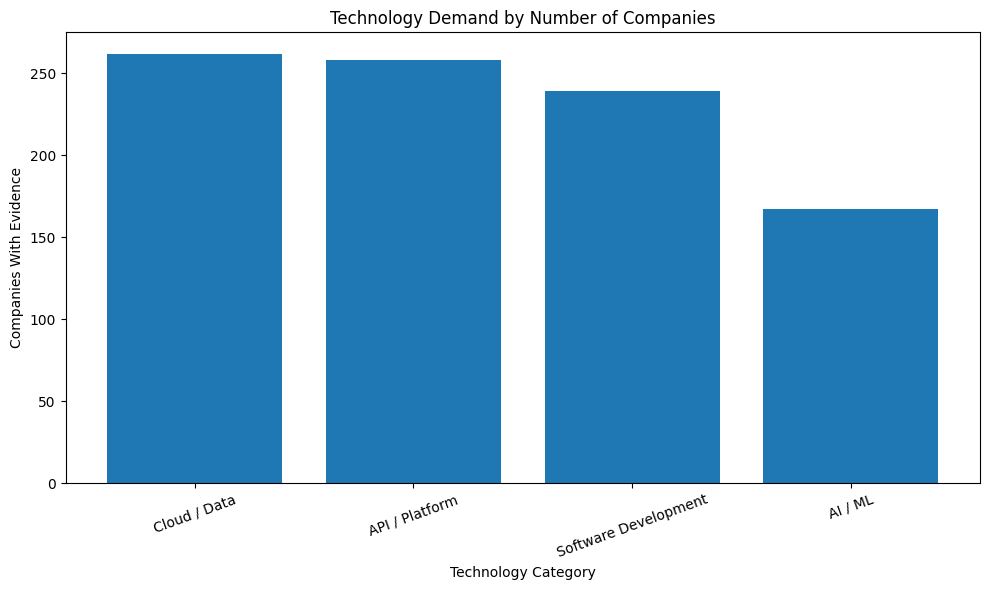

In [23]:
# ============================================================
# TECHNOLOGY DEMAND CHART
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    technology_summary["Technology_Category"],
    technology_summary["Companies_With_Evidence"]
)

plt.title("Technology Demand by Number of Companies")
plt.xlabel("Technology Category")
plt.ylabel("Companies With Evidence")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# TECHNOLOGY BUSINESS INSIGHTS
# ============================================================

top_technology = technology_summary.iloc[0]

print("=" * 60)
print("TECHNOLOGY BUSINESS INSIGHTS")
print("=" * 60)

print(
    f"Strongest technology category: "
    f"{top_technology['Technology_Category']}"
)

print(
    f"Companies showing evidence: "
    f"{int(top_technology['Companies_With_Evidence'])} "
    f"({top_technology['Evidence_Penetration_Percentage']}%)"
)

print(
    f"Total evidence signals: "
    f"{int(top_technology['Total_Evidence'])}"
)

print(
    "\nTechnology categories ranked by company penetration:"
)

for _, row in technology_summary.iterrows():
    print(
        f"- {row['Technology_Category']}: "
        f"{int(row['Companies_With_Evidence'])} companies "
        f"({row['Evidence_Penetration_Percentage']}%)"
    )

TECHNOLOGY BUSINESS INSIGHTS
Strongest technology category: Cloud / Data
Companies showing evidence: 262 (83.71%)
Total evidence signals: 1574

Technology categories ranked by company penetration:
- Cloud / Data: 262 companies (83.71%)
- API / Platform: 258 companies (82.43%)
- Software Development: 239 companies (76.36%)
- AI / ML: 167 companies (53.35%)


In [25]:
# ============================================================
# MARKETING READINESS ANALYSIS
# ============================================================

print("=" * 60)
print("MARKETING READINESS BUSINESS ANALYSIS")
print("=" * 60)

# Distribution
print("\nMarketing Readiness V2 Distribution:")
print(
    business_df["Marketing Readiness V2"]
    .value_counts(dropna=False)
)

# Average prospect score by marketing readiness
marketing_analysis = (
    business_df
    .groupby("Marketing Readiness V2", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        Average_Prospect_Score=("Prospect Score V2", "mean"),
        Average_Technology_Fit=("Technology Fit Score V2", "mean"),
        Tier_1_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 1 - High Priority").sum()
        ),
        Tier_2_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 2 - Priority").sum()
        )
    )
    .reset_index()
)

marketing_analysis[
    [
        "Average_Prospect_Score",
        "Average_Technology_Fit"
    ]
] = marketing_analysis[
    [
        "Average_Prospect_Score",
        "Average_Technology_Fit"
    ]
].round(2)

print("\nMarketing Readiness Analysis:")
print(marketing_analysis.to_string(index=False))

# Save output
marketing_analysis.to_csv(
    os.path.join(
        analysis_dir,
        "Marketing_Readiness_Analysis.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

print("\nCreated:")
print("06_Analysis\\Marketing_Readiness_Analysis.csv")

MARKETING READINESS BUSINESS ANALYSIS

Marketing Readiness V2 Distribution:
Marketing Readiness V2
High Potential           158
Medium Potential          80
Needs Validation          55
Insufficient Evidence     20
Name: count, dtype: int64

Marketing Readiness Analysis:
Marketing Readiness V2  Company_Count  Average_Prospect_Score  Average_Technology_Fit  Tier_1_Leads  Tier_2_Leads
        High Potential            158                   82.67                   23.00            40            82
 Insufficient Evidence             20                   15.45                    0.00             0             0
      Medium Potential             80                   57.78                   21.42             0             4
      Needs Validation             55                   30.40                    7.98             0             0

Created:
06_Analysis\Marketing_Readiness_Analysis.csv


In [26]:
# ============================================================
# HIGH-VALUE MARKETING-READY LEADS
# ============================================================

marketing_ready_leads = business_df[
    (
        business_df["Marketing Readiness V2"]
        .astype(str)
        .str.contains("High", case=False, na=False)
    )
    &
    (
        business_df["Prospect Score V2"] >= 70
    )
].sort_values(
    "Prospect Score V2",
    ascending=False
)

print("High-value marketing-ready leads:")
print("Records:", len(marketing_ready_leads))

print(
    marketing_ready_leads[
        [
            "Company Name",
            "Industry_Standardized",
            "Marketing Readiness V2",
            "Technology Fit Score V2",
            "Prospect Score V2",
            "Lead Priority V2"
        ]
    ].head(50).to_string(index=False)
)

High-value marketing-ready leads:
Records: 138
               Company Name    Industry_Standardized Marketing Readiness V2  Technology Fit Score V2  Prospect Score V2       Lead Priority V2
                     Amazon   Information Technology         High Potential                       25                 99 Tier 1 - High Priority
                       Meta   Information Technology         High Potential                       25                 99 Tier 1 - High Priority
                     Oracle   Information Technology         High Potential                       25                 99 Tier 1 - High Priority
        State Bank of India                  Banking         High Potential                       25                 99 Tier 1 - High Priority
                    Verizon   Information Technology         High Potential                       25                 99 Tier 1 - High Priority
              Bajaj Finserv       Financial Services         High Potential                    

In [27]:
# ============================================================
# 4. COMPANY SIZE OPPORTUNITY ANALYSIS
# ============================================================

print("=" * 60)
print("COMPANY SIZE OPPORTUNITY ANALYSIS")
print("=" * 60)

size_analysis = (
    business_df
    .groupby("Company Size Category", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        Average_Prospect_Score=("Prospect Score V2", "mean"),
        Average_Technology_Fit=("Technology Fit Score V2", "mean"),
        Average_Company_Fit=("Company Fit Score", "mean"),
        Average_Growth_Intent=("Growth Intent Score", "mean"),
        Average_Funding_Expansion=("Funding Expansion Score", "mean"),
        Average_Marketing_Readiness=("Marketing Readiness Score", "mean"),
        Tier_1_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 1 - High Priority").sum()
        ),
        Tier_2_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 2 - Priority").sum()
        )
    )
    .reset_index()
)

average_columns = [
    "Average_Prospect_Score",
    "Average_Technology_Fit",
    "Average_Company_Fit",
    "Average_Growth_Intent",
    "Average_Funding_Expansion",
    "Average_Marketing_Readiness"
]

size_analysis[average_columns] = (
    size_analysis[average_columns].round(2)
)

# Tier 1 percentage
size_analysis["Tier_1_Percentage"] = (
    size_analysis["Tier_1_Leads"]
    / size_analysis["Company_Count"]
    * 100
).round(2)

# Sort by average prospect score
size_analysis = size_analysis.sort_values(
    "Average_Prospect_Score",
    ascending=False
)

print("\nCompany Size Opportunities:")
print(size_analysis.to_string(index=False))

# Save
size_file = os.path.join(
    analysis_dir,
    "Company_Size_Opportunity_Analysis.csv"
)

size_analysis.to_csv(
    size_file,
    index=False,
    encoding="utf-8-sig"
)

print("\nCreated:")
print(size_file)

COMPANY SIZE OPPORTUNITY ANALYSIS

Company Size Opportunities:
Company Size Category  Company_Count  Average_Prospect_Score  Average_Technology_Fit  Average_Company_Fit  Average_Growth_Intent  Average_Funding_Expansion  Average_Marketing_Readiness  Tier_1_Leads  Tier_2_Leads  Tier_1_Percentage
           Enterprise            114                   74.08                   22.47                15.68                  11.93                       5.83                         8.79            14            47              12.28
     Large Enterprise             75                   72.33                   20.52                16.97                  10.40                       7.67                         7.79            24            16              32.00
           Mid-Market             72                   63.75                   19.31                 9.92                  11.39                       5.69                         8.00             2            23               2.78
         

In [28]:
# ============================================================
# BEST COMPANY SIZE SEGMENTS
# ============================================================

print("=" * 60)
print("BEST COMPANY SIZE SEGMENTS")
print("=" * 60)

best_size_segments = size_analysis[
    size_analysis["Company_Count"] >= 3
].sort_values(
    ["Average_Prospect_Score", "Tier_1_Percentage"],
    ascending=[False, False]
)

print(
    best_size_segments[
        [
            "Company Size Category",
            "Company_Count",
            "Average_Prospect_Score",
            "Tier_1_Leads",
            "Tier_2_Leads",
            "Tier_1_Percentage"
        ]
    ].to_string(index=False)
)

BEST COMPANY SIZE SEGMENTS
Company Size Category  Company_Count  Average_Prospect_Score  Tier_1_Leads  Tier_2_Leads  Tier_1_Percentage
           Enterprise            114                   74.08            14            47              12.28
     Large Enterprise             75                   72.33            24            16              32.00
           Mid-Market             72                   63.75             2            23               2.78
                  SME              5                   39.60             0             0               0.00
      Startup / Small             39                   23.54             0             0               0.00
   Needs Verification              8                   11.12             0             0               0.00


In [29]:
# ============================================================
# 5. LOCATION OPPORTUNITY ANALYSIS
# ============================================================

print("=" * 60)
print("LOCATION OPPORTUNITY ANALYSIS")
print("=" * 60)

location_analysis = (
    business_df
    .groupby("Country_Standardized", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        Average_Prospect_Score=("Prospect Score V2", "mean"),
        Average_Technology_Fit=("Technology Fit Score V2", "mean"),
        Average_Company_Fit=("Company Fit Score", "mean"),
        Average_Growth_Intent=("Growth Intent Score", "mean"),
        Average_Funding_Expansion=("Funding Expansion Score", "mean"),
        Average_Marketing_Readiness=("Marketing Readiness Score", "mean"),
        Tier_1_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 1 - High Priority").sum()
        ),
        Tier_2_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 2 - Priority").sum()
        )
    )
    .reset_index()
)

average_columns = [
    "Average_Prospect_Score",
    "Average_Technology_Fit",
    "Average_Company_Fit",
    "Average_Growth_Intent",
    "Average_Funding_Expansion",
    "Average_Marketing_Readiness"
]

location_analysis[average_columns] = (
    location_analysis[average_columns].round(2)
)

location_analysis["Tier_1_Percentage"] = (
    location_analysis["Tier_1_Leads"]
    / location_analysis["Company_Count"]
    * 100
).round(2)

location_analysis = location_analysis.sort_values(
    ["Average_Prospect_Score", "Tier_1_Percentage"],
    ascending=[False, False]
)

print("\nLocation Opportunities:")
print(location_analysis.to_string(index=False))

# Save
location_file = os.path.join(
    analysis_dir,
    "Location_Opportunity_Analysis.csv"
)

location_analysis.to_csv(
    location_file,
    index=False,
    encoding="utf-8-sig"
)

print("\nCreated:")
print(location_file)

LOCATION OPPORTUNITY ANALYSIS

Location Opportunities:
Country_Standardized  Company_Count  Average_Prospect_Score  Average_Technology_Fit  Average_Company_Fit  Average_Growth_Intent  Average_Funding_Expansion  Average_Marketing_Readiness  Tier_1_Leads  Tier_2_Leads  Tier_1_Percentage
           Argentina              1                   98.00                   25.00                18.00                  20.00                      15.00                        10.00             1             0             100.00
        Saudi Arabia              1                   97.00                   25.00                17.00                  20.00                      15.00                        10.00             1             0             100.00
               China              3                   94.33                   25.00                19.00                  20.00                      11.67                        10.00             3             0             100.00
              Sweden 

In [30]:
# ============================================================
# TOP LOCATION SEGMENTS
# ============================================================

top_locations = location_analysis[
    location_analysis["Company_Count"] >= 3
].head(15)

print("=" * 60)
print("TOP LOCATION SEGMENTS")
print("=" * 60)

print(
    top_locations[
        [
            "Country_Standardized",
            "Company_Count",
            "Average_Prospect_Score",
            "Tier_1_Leads",
            "Tier_2_Leads",
            "Tier_1_Percentage"
        ]
    ].to_string(index=False)
)

TOP LOCATION SEGMENTS
Country_Standardized  Company_Count  Average_Prospect_Score  Tier_1_Leads  Tier_2_Leads  Tier_1_Percentage
               China              3                   94.33             3             0             100.00
             Germany              4                   69.50             2             0              50.00
       United States             76                   67.97            15            21              19.74
               India            169                   65.58            17            55              10.06
              France              7                   65.00             0             2               0.00
              Brazil             10                   59.40             0             3               0.00
           Australia              4                   55.50             0             1               0.00
      United Kingdom              9                   43.33             0             2               0.00
              C

In [32]:
# ============================================================
# 6. FINAL BUSINESS RECOMMENDATIONS - SELF CONTAINED
# ============================================================

import os
import pandas as pd

print("=" * 60)
print("FINAL BUSINESS RECOMMENDATIONS")
print("=" * 60)

# ------------------------------------------------------------
# CHECK REQUIRED DATA
# ------------------------------------------------------------

required_columns = [
    "Company Name",
    "Industry_Standardized",
    "Company Size Category",
    "Marketing Readiness V2",
    "Prospect Score V2",
    "Technology Fit Score V2",
    "Company Fit Score",
    "Growth Intent Score",
    "Funding Expansion Score",
    "Marketing Readiness Score",
    "Lead Priority V2",
    "AI Evidence Count",
    "Cloud/Data Evidence Count",
    "API/Platform Evidence Count",
    "Software Development Evidence Count"
]

missing = [
    col for col in required_columns
    if col not in business_df.columns
]

if missing:
    print("Missing columns:")
    print(missing)
    raise KeyError("Required columns are missing from business_df.")

print("Required columns: OK")


# ------------------------------------------------------------
# 1. INDUSTRY ANALYSIS
# ------------------------------------------------------------

industry_analysis = (
    business_df
    .groupby("Industry_Standardized", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        Average_Prospect_Score=("Prospect Score V2", "mean"),
        Average_Technology_Fit=("Technology Fit Score V2", "mean"),
        Tier_1_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 1 - High Priority").sum()
        ),
        Tier_2_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 2 - Priority").sum()
        )
    )
    .reset_index()
)

industry_analysis[
    [
        "Average_Prospect_Score",
        "Average_Technology_Fit"
    ]
] = industry_analysis[
    [
        "Average_Prospect_Score",
        "Average_Technology_Fit"
    ]
].round(2)

industry_candidates = industry_analysis[
    industry_analysis["Company_Count"] >= 3
].sort_values(
    "Average_Prospect_Score",
    ascending=False
)

top_industry = industry_candidates.iloc[0]


# ------------------------------------------------------------
# 2. COMPANY SIZE ANALYSIS
# ------------------------------------------------------------

size_analysis = (
    business_df
    .groupby("Company Size Category", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        Average_Prospect_Score=("Prospect Score V2", "mean"),
        Tier_1_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 1 - High Priority").sum()
        ),
        Tier_2_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 2 - Priority").sum()
        )
    )
    .reset_index()
)

size_analysis["Average_Prospect_Score"] = (
    size_analysis["Average_Prospect_Score"].round(2)
)

size_analysis["Tier_1_Percentage"] = (
    size_analysis["Tier_1_Leads"]
    / size_analysis["Company_Count"]
    * 100
).round(2)

size_candidates = size_analysis[
    size_analysis["Company_Count"] >= 3
]

best_size = size_candidates.sort_values(
    "Average_Prospect_Score",
    ascending=False
).iloc[0]

best_tier1_size = size_candidates.sort_values(
    "Tier_1_Percentage",
    ascending=False
).iloc[0]


# ------------------------------------------------------------
# 3. MARKETING READINESS
# ------------------------------------------------------------

marketing_analysis = (
    business_df
    .groupby("Marketing Readiness V2", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        Average_Prospect_Score=("Prospect Score V2", "mean")
    )
    .reset_index()
)

marketing_analysis["Average_Prospect_Score"] = (
    marketing_analysis["Average_Prospect_Score"].round(2)
)

best_marketing = marketing_analysis.sort_values(
    "Average_Prospect_Score",
    ascending=False
).iloc[0]


# ------------------------------------------------------------
# 4. TECHNOLOGY ANALYSIS
# ------------------------------------------------------------

technology_totals = {
    "AI / ML": int(business_df["AI Evidence Count"].sum()),
    "Cloud / Data": int(business_df["Cloud/Data Evidence Count"].sum()),
    "API / Platform": int(business_df["API/Platform Evidence Count"].sum()),
    "Software Development": int(
        business_df["Software Development Evidence Count"].sum()
    )
}

strongest_technology = max(
    technology_totals,
    key=technology_totals.get
)


# ------------------------------------------------------------
# 5. LEAD PRIORITY
# ------------------------------------------------------------

priority_counts = business_df["Lead Priority V2"].value_counts()

tier1_count = int(
    priority_counts.get("Tier 1 - High Priority", 0)
)

tier2_count = int(
    priority_counts.get("Tier 2 - Priority", 0)
)


# ------------------------------------------------------------
# 6. BUILD RECOMMENDATIONS
# ------------------------------------------------------------

recommendations = [

    {
        "Analysis_Area": "Industry",
        "Finding": (
            f"{top_industry['Industry_Standardized']} has the "
            f"highest average prospect score among industries "
            f"with at least 3 companies."
        ),
        "Key_Metric": top_industry["Average_Prospect_Score"],
        "Recommended_Action":
            "Prioritize this industry for targeted B2B outreach."
    },

    {
        "Analysis_Area": "Company Size",
        "Finding": (
            f"{best_size['Company Size Category']} has the highest "
            f"average prospect score."
        ),
        "Key_Metric": best_size["Average_Prospect_Score"],
        "Recommended_Action": (
            f"Prioritize {best_size['Company Size Category']} accounts. "
            f"{best_tier1_size['Company Size Category']} has the "
            f"highest Tier 1 concentration."
        )
    },

    {
        "Analysis_Area": "Marketing Readiness",
        "Finding": (
            f"{best_marketing['Marketing Readiness V2']} accounts "
            f"have the highest average prospect score."
        ),
        "Key_Metric": best_marketing["Average_Prospect_Score"],
        "Recommended_Action":
            "Use marketing readiness as a campaign prioritization filter."
    },

    {
        "Analysis_Area": "Technology",
        "Finding": (
            f"{strongest_technology} has the highest total "
            f"technology evidence."
        ),
        "Key_Metric": technology_totals[strongest_technology],
        "Recommended_Action": (
            f"Emphasize {strongest_technology}-related services "
            "in B2B messaging."
        )
    },

    {
        "Analysis_Area": "Lead Priority",
        "Finding": (
            f"{tier1_count} Tier 1 and {tier2_count} Tier 2 leads "
            "represent the main immediate sales opportunity."
        ),
        "Key_Metric": tier1_count + tier2_count,
        "Recommended_Action":
            "Contact Tier 1 first, followed by Tier 2."
    }
]

recommendations_df = pd.DataFrame(recommendations)


# ------------------------------------------------------------
# 7. SAVE
# ------------------------------------------------------------

analysis_dir = "06_Analysis"
os.makedirs(analysis_dir, exist_ok=True)

recommendations_file = os.path.join(
    analysis_dir,
    "Final_Business_Recommendations.csv"
)

recommendations_df.to_csv(
    recommendations_file,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 8. DISPLAY
# ------------------------------------------------------------

print("\nFINAL BUSINESS RECOMMENDATIONS")
print("-" * 60)

print(
    recommendations_df.to_string(index=False)
)

print("\n" + "=" * 60)
print("OUTPUT CREATED")
print("=" * 60)

print(
    "File:",
    recommendations_file
)

FINAL BUSINESS RECOMMENDATIONS
Required columns: OK

FINAL BUSINESS RECOMMENDATIONS
------------------------------------------------------------
      Analysis_Area                                                                                          Finding  Key_Metric                                                                     Recommended_Action
           Industry Entertainment has the highest average prospect score among industries with at least 3 companies.       88.00                                    Prioritize this industry for targeted B2B outreach.
       Company Size                                               Enterprise has the highest average prospect score.       74.08 Prioritize Enterprise accounts. Large Enterprise has the highest Tier 1 concentration.
Marketing Readiness                                 High Potential accounts have the highest average prospect score.       82.67                           Use marketing readiness as a campaign prioritization

In [34]:
import os

print("Current Jupyter folder:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Current Jupyter folder:
C:\Users\Sai\Desktop\New folder

Files/folders here:
['.ipynb_checkpoints', '01_Data_Understanding.ipynb', '01_Raw_Data', '02_Data_Cleaning.ipynb.ipynb', '02_Data_Quality', '03_Data_Dictionary', '04_Clean_Data', '05_Enriched_Data', '05_Final_Output', '06_Analysis', '06_Business_Analysis.ipynb.ipynb', '07_Dashboard', '08_Scripts', '09_Documentation', '10_Final_Submission']


In [35]:
import os

print("\nSearching for enrichment CSV files...")

for root, dirs, files in os.walk("."):
    for file in files:
        if "Enriched" in file or "enrich" in file.lower():
            print(os.path.join(root, file))


Searching for enrichment CSV files...
.\05_Enriched_Data\NexziByte_B2B_Lead_Intelligence_Enriched_V2.csv


In [36]:
import pandas as pd

enriched_df = pd.read_csv(
    "05_Enriched_Data/NexziByte_B2B_Lead_Intelligence_Enriched_V2.csv",
    encoding="utf-8-sig"
)

print("Rows:", len(enriched_df))
print("Columns:", len(enriched_df.columns))

print("\nColumns:")
print(enriched_df.columns.tolist())

Rows: 313
Columns: 31

Columns:
['Company Name', 'Technology Areas Cleaned', 'AI/ML Signals', 'API/Platform Signals', 'Cloud/Data Signals', 'Software Development Signals', 'AI Technology Evidence', 'Cloud/Data Technology Evidence', 'API/Platform Technology Evidence', 'Software Development Evidence', 'AI Evidence Count', 'Cloud/Data Evidence Count', 'API/Platform Evidence Count', 'Software Development Evidence Count', 'Total Technology Evidence', 'High Value AI Terms', 'High Value Cloud Terms', 'High Value Platform Terms', 'High Value Dev Terms', 'High Value Technology Count', 'Technology Fit Score V2', 'Company Fit Score', 'Growth Intent Score', 'Funding Expansion Score', 'Marketing Readiness Score', 'Data Confidence Score', 'Marketing Readiness V2', 'Data Quality Status V2', 'Prospect Score V2', 'Lead Priority V2', 'Prospect Rank V2']


In [37]:
# ============================================================
# STEP 2 — ADD BUSINESS SIGNAL FIELDS
# ============================================================

business_signal_columns = [
    "Automation / Workflow Signals",
    "Hiring Signals",
    "Growth Signals",
    "Expansion Signals",
    "Funding Signals",
    "Product Launch Signals",
    "Partnership Signals",
    "Observed Information",
    "Inferred Opportunity"
]

for col in business_signal_columns:
    if col not in enriched_df.columns:
        enriched_df[col] = "Not Available"

print("=" * 60)
print("BUSINESS SIGNAL FIELDS")
print("=" * 60)

for col in business_signal_columns:
    print(
        "OK" if col in enriched_df.columns else "MISSING",
        "->",
        col
    )

print("\nRows:", len(enriched_df))
print("Columns:", len(enriched_df.columns))

BUSINESS SIGNAL FIELDS
OK -> Automation / Workflow Signals
OK -> Hiring Signals
OK -> Growth Signals
OK -> Expansion Signals
OK -> Funding Signals
OK -> Product Launch Signals
OK -> Partnership Signals
OK -> Observed Information
OK -> Inferred Opportunity

Rows: 313
Columns: 40


In [38]:
# ============================================================
# STEP 3 — CHECK AVAILABLE SOURCE FIELDS
# ============================================================

print("=" * 60)
print("AVAILABLE SOURCE FIELDS")
print("=" * 60)

source_candidates = [
    "Company Name",
    "Contact",
    "Designation",
    "Job Title",
    "Title",
    "Industry",
    "Industry_Standardized",
    "Technology Areas",
    "Technology Areas Cleaned",
    "AI/ML Signals",
    "API/Platform Signals",
    "Cloud/Data Signals",
    "Software Development Signals",
    "Hiring/Growth Signals",
    "Funding/Expansion Signals",
    "Keywords",
    "Products / Services",
    "Business Model",
    "Website",
    "Company Linkedin Url",
    "Total Funding",
    "Latest Funding",
    "Latest Funding Amount",
    "Last Raised At"
]

for col in source_candidates:
    if col in enriched_df.columns:
        non_empty = enriched_df[col].notna().sum()
        print(f"OK       {col:<35} {non_empty} non-empty")
    else:
        print(f"MISSING  {col}")

AVAILABLE SOURCE FIELDS
OK       Company Name                        313 non-empty
MISSING  Contact
MISSING  Designation
MISSING  Job Title
MISSING  Title
MISSING  Industry
MISSING  Industry_Standardized
MISSING  Technology Areas
OK       Technology Areas Cleaned            313 non-empty
OK       AI/ML Signals                       313 non-empty
OK       API/Platform Signals                313 non-empty
OK       Cloud/Data Signals                  313 non-empty
OK       Software Development Signals        313 non-empty
MISSING  Hiring/Growth Signals
MISSING  Funding/Expansion Signals
MISSING  Keywords
MISSING  Products / Services
MISSING  Business Model
MISSING  Website
MISSING  Company Linkedin Url
MISSING  Total Funding
MISSING  Latest Funding
MISSING  Latest Funding Amount
MISSING  Last Raised At


In [39]:
# ============================================================
# STEP 3B — CHECK EXISTING BUSINESS SIGNAL DATA
# ============================================================

signal_columns = [
    "Hiring/Growth Signals",
    "Funding/Expansion Signals",
    "AI/ML Signals",
    "API/Platform Signals",
    "Cloud/Data Signals",
    "Software Development Signals"
]

print("=" * 60)
print("EXISTING SIGNAL COVERAGE")
print("=" * 60)

for col in signal_columns:
    if col in enriched_df.columns:
        print(f"\n--- {col} ---")
        print(
            enriched_df[col]
            .fillna("Not Available")
            .value_counts()
            .head(10)
        )

EXISTING SIGNAL COVERAGE

--- AI/ML Signals ---
AI/ML Signals
Observed in supplied Apollo data    245
Not Available                        68
Name: count, dtype: int64

--- API/Platform Signals ---
API/Platform Signals
Observed in supplied Apollo data    259
Not Available                        54
Name: count, dtype: int64

--- Cloud/Data Signals ---
Cloud/Data Signals
Observed in supplied Apollo data    255
Not Available                        58
Name: count, dtype: int64

--- Software Development Signals ---
Software Development Signals
Observed in supplied Apollo data    282
Not Available                        31
Name: count, dtype: int64


In [40]:
# ============================================================
# STEP 4 — CHECK AVAILABLE DATAFRAMES
# ============================================================

print("=" * 60)
print("AVAILABLE DATAFRAMES")
print("=" * 60)

for name, obj in list(globals().items()):
    if hasattr(obj, "shape") and hasattr(obj, "columns"):
        print(
            f"{name:<30} "
            f"Rows: {obj.shape[0]:<5} "
            f"Columns: {obj.shape[1]}"
        )

AVAILABLE DATAFRAMES
business_df                    Rows: 313   Columns: 83
executive_kpi                  Rows: 12    Columns: 2
prospect_distribution          Rows: 79    Columns: 3
lead_priority_analysis         Rows: 4     Columns: 3
size_analysis                  Rows: 6     Columns: 6
size_opportunities             Rows: 6     Columns: 11
geo_analysis                   Rows: 29    Columns: 11
geo_opportunities              Rows: 10    Columns: 11
country_concentration          Rows: 29    Columns: 3
technology_summary             Rows: 4     Columns: 5
technology_strength            Rows: 313   Columns: 8
technology_by_industry         Rows: 57    Columns: 7
marketing_analysis             Rows: 4     Columns: 3
marketing_ready_leads          Rows: 138   Columns: 83
best_size_segments             Rows: 6     Columns: 11
location_analysis              Rows: 29    Columns: 11
top_locations                  Rows: 10    Columns: 11
industry_analysis              Rows: 57    Columns: 6

In [41]:
# ============================================================
# STEP 4B — FIND THE DATAFRAME WITH ORIGINAL BUSINESS FIELDS
# ============================================================

candidate_fields = [
    "Contact",
    "Designation",
    "Hiring/Growth Signals",
    "Funding/Expansion Signals",
    "Industry_Standardized",
    "Website",
    "Keywords"
]

for name, obj in list(globals().items()):
    if hasattr(obj, "columns"):
        found = [
            col for col in candidate_fields
            if col in obj.columns
        ]

        if found:
            print(f"\n{name}")
            print("Matching fields:", found)


business_df
Matching fields: ['Contact', 'Hiring/Growth Signals', 'Funding/Expansion Signals', 'Industry_Standardized', 'Website', 'Keywords']

technology_by_industry
Matching fields: ['Industry_Standardized']

marketing_ready_leads
Matching fields: ['Contact', 'Hiring/Growth Signals', 'Funding/Expansion Signals', 'Industry_Standardized', 'Website', 'Keywords']

industry_analysis
Matching fields: ['Industry_Standardized']

industry_candidates
Matching fields: ['Industry_Standardized']


In [42]:
# ============================================================
# STEP 5 — RESTORE ORIGINAL BUSINESS / SOURCE FIELDS
# ============================================================

fields_to_restore = [
    "Contact",
    "Hiring/Growth Signals",
    "Funding/Expansion Signals",
    "Industry_Standardized",
    "Website",
    "Keywords"
]

# Keep only fields that exist in business_df
available_restore_fields = [
    col for col in fields_to_restore
    if col in business_df.columns
]

# Avoid duplicate Company Name during merge
restore_df = business_df[
    ["Company Name"] + available_restore_fields
].copy()

# Remove duplicate companies before merging
restore_df = restore_df.drop_duplicates(
    subset=["Company Name"],
    keep="first"
)

# Remove existing versions of these columns from enriched_df
# so the merge does not create _x / _y columns.
enriched_df = enriched_df.drop(
    columns=[
        col for col in available_restore_fields
        if col in enriched_df.columns
    ],
    errors="ignore"
)

# Merge using Company Name
enriched_df = enriched_df.merge(
    restore_df,
    on="Company Name",
    how="left"
)

print("=" * 60)
print("ORIGINAL BUSINESS FIELDS RESTORED")
print("=" * 60)

print("Rows:", len(enriched_df))
print("Columns:", len(enriched_df.columns))

for col in available_restore_fields:
    print(
        f"{col}:",
        enriched_df[col].notna().sum(),
        "non-empty"
    )

ORIGINAL BUSINESS FIELDS RESTORED
Rows: 313
Columns: 46
Contact: 313 non-empty
Hiring/Growth Signals: 313 non-empty
Funding/Expansion Signals: 313 non-empty
Industry_Standardized: 313 non-empty
Website: 313 non-empty
Keywords: 313 non-empty


In [43]:
# ============================================================
# STEP 5B — MERGE VALIDATION
# ============================================================

print("=" * 60)
print("MERGE VALIDATION")
print("=" * 60)

print("Expected rows: 313")
print("Actual rows:", len(enriched_df))

print("\nRequired restored fields:")

for col in [
    "Contact",
    "Hiring/Growth Signals",
    "Funding/Expansion Signals",
    "Industry_Standardized",
    "Website",
    "Keywords"
]:
    if col in enriched_df.columns:
        print(
            "OK   ",
            col,
            "->",
            enriched_df[col].notna().sum(),
            "non-empty"
        )
    else:
        print("MISS ", col)

print("\nDuplicate Company Names:")
print(
    enriched_df["Company Name"]
    .duplicated()
    .sum()
)

MERGE VALIDATION
Expected rows: 313
Actual rows: 313

Required restored fields:
OK    Contact -> 313 non-empty
OK    Hiring/Growth Signals -> 313 non-empty
OK    Funding/Expansion Signals -> 313 non-empty
OK    Industry_Standardized -> 313 non-empty
OK    Website -> 313 non-empty
OK    Keywords -> 313 non-empty

Duplicate Company Names:
6


In [44]:
# ============================================================
# STEP 6 — INSPECT DUPLICATE COMPANY NAMES
# ============================================================

duplicate_companies = (
    enriched_df[
        enriched_df["Company Name"].duplicated(keep=False)
    ]
    .sort_values("Company Name")
)

print("=" * 60)
print("DUPLICATE COMPANY NAME REVIEW")
print("=" * 60)

print(
    duplicate_companies[
        [
            "Company Name",
            "Contact",
            "Website",
            "Industry_Standardized",
            "Hiring/Growth Signals",
            "Funding/Expansion Signals"
        ]
    ].to_string(index=False)
)

DUPLICATE COMPANY NAME REVIEW
  Company Name         Contact                           Website  Industry_Standardized            Hiring/Growth Signals        Funding/Expansion Signals
Mister Postman +1 206-767-8047   http://www.heymisterpostman.com  Management Consulting Observed in supplied Apollo data                    Not Available
Mister Postman +1 206-767-8047   http://www.heymisterpostman.com  Management Consulting Observed in supplied Apollo data                    Not Available
       Postman +1 415-796-6470            http://www.postman.com Information Technology                    Not Available Observed in supplied Apollo data
       Postman +1 415-796-6470            http://www.postman.com Information Technology                    Not Available Observed in supplied Apollo data
       Postman +1 415-796-6470            http://www.postman.com Information Technology                    Not Available Observed in supplied Apollo data
       Postman +1 415-796-6470            http

In [45]:
# ============================================================
# STEP 6B — DUPLICATE COMPANY SUMMARY
# ============================================================

duplicate_summary = (
    enriched_df
    .groupby("Company Name")
    .size()
    .reset_index(name="Record_Count")
)

duplicate_summary = duplicate_summary[
    duplicate_summary["Record_Count"] > 1
].sort_values(
    "Record_Count",
    ascending=False
)

print(duplicate_summary.to_string(index=False))

  Company Name  Record_Count
       Postman             5
Mister Postman             2
   The Postman             2


In [46]:
# ============================================================
# STEP 7 — DETAILED DUPLICATE COMPANY REVIEW
# ============================================================

duplicate_names = [
    "Postman",
    "Mister Postman",
    "The Postman"
]

duplicate_review = enriched_df[
    enriched_df["Company Name"].isin(duplicate_names)
].copy()

review_columns = [
    "Company Name",
    "Contact",
    "Website",
    "Industry_Standardized",
    "Keywords",
    "Technology Areas Cleaned",
    "Hiring/Growth Signals",
    "Funding/Expansion Signals",
    "Marketing Readiness V2",
    "Data Quality Status V2",
    "Prospect Score V2",
    "Lead Priority V2"
]

review_columns = [
    col for col in review_columns
    if col in duplicate_review.columns
]

print("=" * 80)
print("DUPLICATE COMPANY DETAILED REVIEW")
print("=" * 80)

print(
    duplicate_review[review_columns]
    .to_string(index=False)
)

DUPLICATE COMPANY DETAILED REVIEW
  Company Name         Contact                           Website  Industry_Standardized                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

In [47]:
# ============================================================
# STEP 7B — DUPLICATE RECORD COMPARISON
# ============================================================

for company in duplicate_names:

    temp = duplicate_review[
        duplicate_review["Company Name"] == company
    ]

    print("\n" + "=" * 60)
    print(company)
    print("=" * 60)

    for col in [
        "Contact",
        "Website",
        "Industry_Standardized",
        "Keywords"
    ]:
        if col in temp.columns:
            print(f"\n{col}:")
            print(temp[col].fillna("Missing").tolist())


Postman

Contact:
['+1 415-796-6470', '+1 415-796-6470', '+1 415-796-6470', '+1 415-796-6470', '+1 415-796-6470']

Website:
['http://www.postman.com', 'http://www.postman.com', 'http://www.postman.com', 'http://www.postman.com', 'http://www.postman.com']

Industry_Standardized:
['Information Technology', 'Information Technology', 'Information Technology', 'Information Technology', 'Information Technology']

Keywords:
['software, apis, api development, saas, api management, developer tools, web development, cloud infrastructure, enterprise software, information technology, software development, api platform, api lifecycle tools, api security threat mitigation, api security vulnerability management, api data security, api testing tools, api version control, api security incident management, api mock servers, devops, api automation, api security incident response, retail, api security risk assessment, automotive, api vulnerability scanning, api design, api lifecycle management, api analy

In [48]:
# ============================================================
# STEP 8 — REMOVE CONFIRMED DUPLICATE COMPANY RECORDS
# ============================================================

before_count = len(enriched_df)

# Remove exact duplicate company records.
# Keep the first record for each Company Name.
enriched_df = enriched_df.drop_duplicates(
    subset=["Company Name"],
    keep="first"
).copy()

after_count = len(enriched_df)

print("=" * 60)
print("DUPLICATE COMPANY CLEANING")
print("=" * 60)

print("Records before:", before_count)
print("Records after :", after_count)
print("Records removed:", before_count - after_count)

print("\nRemaining duplicate Company Names:")
print(
    enriched_df["Company Name"]
    .duplicated()
    .sum()
)

DUPLICATE COMPANY CLEANING
Records before: 313
Records after : 307
Records removed: 6

Remaining duplicate Company Names:
0


In [49]:
# ============================================================
# STEP 9 — INSPECT CONTACT FIELD
# ============================================================

print("=" * 60)
print("CONTACT FIELD REVIEW")
print("=" * 60)

print("Total records:", len(enriched_df))
print("Non-empty contacts:", enriched_df["Contact"].notna().sum())

print("\nSample Contact values:")
print(
    enriched_df["Contact"]
    .dropna()
    .astype(str)
    .head(30)
    .to_string(index=False)
)

CONTACT FIELD REVIEW
Total records: 307
Non-empty contacts: 307

Sample Contact values:
  +1 206-266-1000
  +1 650-543-4800
  +1 737-867-1000
  +91 94491 12211
  +1 212-395-1000
 +91 20 7157 6072
  +1 678-259-9860
 +91 22 6752 5656
    Not Available
  +49 6227 747474
  +1 800-664-9073
  +91 22666 58282
  +1 800-314-3291
 +91 22 7132 5500
 +49 89 758000282
  +1 415-298-5539
  +91 22666 58282
  +91 22674 59000
    Not Available
  +1 800-747-0583
 +86 424 351 0993
  +91 93139 31393
  +91 79265 65555
  +1 408-996-1010
  +1 650-857-1501
+86 755 2878 0808
  +1 650-687-3600
    Not Available
 +46 10 719 00 00
  +91 22397 60711


In [50]:
# ============================================================
# STEP 9B — CONTACT DATA TYPE CHECK
# ============================================================

print("=" * 60)
print("CONTACT DATA QUALITY")
print("=" * 60)

contact_text = (
    enriched_df["Contact"]
    .fillna("")
    .astype(str)
    .str.strip()
)

print("Blank contacts:", (contact_text == "").sum())

print("\nExamples containing possible role/title terms:")

role_terms = [
    "CEO", "CTO", "CIO", "COO", "CPO",
    "Founder", "Co-Founder",
    "VP", "Vice President",
    "Head", "Director",
    "Manager", "Engineer",
    "Architect",
    "Product",
    "Technology",
    "HR", "Recruiter",
    "Marketing"
]

mask = contact_text.str.contains(
    "|".join(role_terms),
    case=False,
    regex=True,
    na=False
)

print("Possible role/title records:", mask.sum())

print(
    enriched_df.loc[
        mask,
        ["Company Name", "Contact"]
    ]
    .head(50)
    .to_string(index=False)
)

CONTACT DATA QUALITY
Blank contacts: 0

Examples containing possible role/title terms:
Possible role/title records: 0
Empty DataFrame
Columns: [Company Name, Contact]
Index: []


In [51]:
# ============================================================
# STEP 10 — PERSONA CLASSIFICATION
# ============================================================

enriched_df["Persona"] = "Unknown / Not Available"
enriched_df["Persona Category"] = "Other"
enriched_df["Persona Relevance"] = "Cannot Determine"
enriched_df["Persona Evidence"] = (
    "No contact designation/title available in supplied dataset"
)

print("=" * 60)
print("PERSONA CLASSIFICATION")
print("=" * 60)

print(
    enriched_df["Persona"]
    .value_counts()
)

print("\nPersona Category:")
print(
    enriched_df["Persona Category"]
    .value_counts()
)

PERSONA CLASSIFICATION
Persona
Unknown / Not Available    307
Name: count, dtype: int64

Persona Category:
Persona Category
Other    307
Name: count, dtype: int64


In [52]:
# ============================================================
# STEP 10B — PERSONA DATA AVAILABILITY
# ============================================================

enriched_df["Persona Data Status"] = "Needs Verification"

print("=" * 60)
print("PERSONA DATA STATUS")
print("=" * 60)

print(
    enriched_df["Persona Data Status"]
    .value_counts()
)

PERSONA DATA STATUS
Persona Data Status
Needs Verification    307
Name: count, dtype: int64


In [53]:
# ============================================================
# STEP 11 — NEXZIBYTE SERVICE OPPORTUNITY MAPPING
# ============================================================

def service_mapping(row):
    scores = {
        "AI / AI Agents": row.get("AI Evidence Count", 0),
        "Cloud / Data Engineering": row.get("Cloud/Data Evidence Count", 0),
        "Backend / API Development": row.get("API/Platform Evidence Count", 0),
        "Custom Software Development": row.get(
            "Software Development Evidence Count", 0
        )
    }

    # Convert safely to numbers
    scores = {
        k: pd.to_numeric(v, errors="coerce") or 0
        for k, v in scores.items()
    }

    ranked = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    primary = ranked[0][0]
    primary_score = ranked[0][1]

    secondary = "Not Available"

    if len(ranked) > 1 and ranked[1][1] > 0:
        secondary = ranked[1][0]

    if primary_score == 0:
        primary = "No Evidence Available"
        secondary = "Not Available"
        reason = (
            "No technology evidence available to infer "
            "a NexziByte service opportunity."
        )
    else:
        reason = (
            f"Potential opportunity inferred from observed "
            f"{primary} technology evidence."
        )

    return pd.Series([
        primary,
        secondary,
        reason
    ])


enriched_df[
    [
        "Primary Service Opportunity",
        "Secondary Service Opportunity",
        "Service Opportunity Reason"
    ]
] = enriched_df.apply(
    service_mapping,
    axis=1
)

print("=" * 60)
print("SERVICE OPPORTUNITY MAPPING")
print("=" * 60)

print("\nPrimary Service Opportunities:")
print(
    enriched_df["Primary Service Opportunity"]
    .value_counts()
)

print("\nSecondary Service Opportunities:")
print(
    enriched_df["Secondary Service Opportunity"]
    .value_counts()
)

SERVICE OPPORTUNITY MAPPING

Primary Service Opportunities:
Primary Service Opportunity
Custom Software Development    178
Cloud / Data Engineering        66
No Evidence Available           32
Backend / API Development       31
Name: count, dtype: int64

Secondary Service Opportunities:
Secondary Service Opportunity
Cloud / Data Engineering       169
Not Available                   57
Backend / API Development       50
Custom Software Development     27
AI / AI Agents                   4
Name: count, dtype: int64


In [54]:
# ============================================================
# STEP 12 — MARKETING SEGMENTATION
# ============================================================

def create_marketing_segment(row):

    ai = pd.to_numeric(row.get("AI Evidence Count", 0), errors="coerce")
    cloud = pd.to_numeric(row.get("Cloud/Data Evidence Count", 0), errors="coerce")
    api = pd.to_numeric(row.get("API/Platform Evidence Count", 0), errors="coerce")
    software = pd.to_numeric(
        row.get("Software Development Evidence Count", 0),
        errors="coerce"
    )

    if pd.isna(ai):
        ai = 0
    if pd.isna(cloud):
        cloud = 0
    if pd.isna(api):
        api = 0
    if pd.isna(software):
        software = 0

    segments = []

    if ai > 0:
        segments.append("AI/ML Companies")

    if cloud > 0:
        segments.append("Cloud/Data Companies")

    if api > 0:
        segments.append("API/Platform Companies")

    if software > 0:
        segments.append("Software Development Prospects")

    if (
        row.get("Hiring/Growth Signals", "Not Available")
        != "Not Available"
    ):
        segments.append("Hiring/Growth Companies")

    if (
        row.get("Funding/Expansion Signals", "Not Available")
        != "Not Available"
    ):
        segments.append("Funding/Expansion Companies")

    if not segments:
        return "General Prospect"

    return " | ".join(segments)


enriched_df["Marketing Segment"] = enriched_df.apply(
    create_marketing_segment,
    axis=1
)

print("=" * 60)
print("MARKETING SEGMENTATION")
print("=" * 60)

print(
    enriched_df["Marketing Segment"]
    .value_counts()
    .head(30)
)

MARKETING SEGMENTATION
Marketing Segment
AI/ML Companies | Cloud/Data Companies | API/Platform Companies | Software Development Prospects | Hiring/Growth Companies | Funding/Expansion Companies    64
AI/ML Companies | Cloud/Data Companies | API/Platform Companies | Software Development Prospects                                                            48
Cloud/Data Companies | API/Platform Companies | Software Development Prospects | Hiring/Growth Companies | Funding/Expansion Companies                      35
AI/ML Companies | Cloud/Data Companies | API/Platform Companies | Software Development Prospects | Hiring/Growth Companies                                  30
General Prospect                                                                                                                                            26
AI/ML Companies | Cloud/Data Companies | API/Platform Companies | Software Development Prospects | Funding/Expansion Companies                              21
Cloud

In [55]:
# ============================================================
# STEP 12B — SEGMENT REASON
# ============================================================

def segment_reason(row):

    reasons = []

    if pd.to_numeric(
        row.get("AI Evidence Count", 0),
        errors="coerce"
    ) > 0:
        reasons.append("AI/ML evidence")

    if pd.to_numeric(
        row.get("Cloud/Data Evidence Count", 0),
        errors="coerce"
    ) > 0:
        reasons.append("Cloud/Data evidence")

    if pd.to_numeric(
        row.get("API/Platform Evidence Count", 0),
        errors="coerce"
    ) > 0:
        reasons.append("API/Platform evidence")

    if pd.to_numeric(
        row.get("Software Development Evidence Count", 0),
        errors="coerce"
    ) > 0:
        reasons.append("Software development evidence")

    if not reasons:
        return "No qualifying technology evidence available"

    return "Observed: " + ", ".join(reasons)


enriched_df["Segment Reason"] = enriched_df.apply(
    segment_reason,
    axis=1
)

print("Segment reasons created.")

Segment reasons created.


In [56]:
# ============================================================
# STEP 12C — SEGMENT VALIDATION
# ============================================================

print("=" * 60)
print("SEGMENT VALIDATION")
print("=" * 60)

print("Rows:", len(enriched_df))

print(
    "\nMissing Marketing Segment:",
    enriched_df["Marketing Segment"].isna().sum()
)

print(
    "Missing Segment Reason:",
    enriched_df["Segment Reason"].isna().sum()
)

print("\nTop segments:")
print(
    enriched_df["Marketing Segment"]
    .value_counts()
    .head(20)
)

SEGMENT VALIDATION
Rows: 307

Missing Marketing Segment: 0
Missing Segment Reason: 0

Top segments:
Marketing Segment
AI/ML Companies | Cloud/Data Companies | API/Platform Companies | Software Development Prospects | Hiring/Growth Companies | Funding/Expansion Companies    64
AI/ML Companies | Cloud/Data Companies | API/Platform Companies | Software Development Prospects                                                            48
Cloud/Data Companies | API/Platform Companies | Software Development Prospects | Hiring/Growth Companies | Funding/Expansion Companies                      35
AI/ML Companies | Cloud/Data Companies | API/Platform Companies | Software Development Prospects | Hiring/Growth Companies                                  30
General Prospect                                                                                                                                            26
AI/ML Companies | Cloud/Data Companies | API/Platform Companies | Software Development 

In [57]:
# ============================================================
# STEP 13 — CAMPAIGN INTELLIGENCE
# ============================================================

def campaign_intelligence(row):

    segment = str(row.get("Marketing Segment", ""))

    if "AI/ML Companies" in segment:
        service = "AI / AI Agents"
        angle = "AI product development, integration or enhancement"
        reason = "Observed AI/ML technology evidence"

    elif "Cloud/Data Companies" in segment:
        service = "Cloud / Data Engineering"
        angle = "Cloud modernization, data engineering and analytics"
        reason = "Observed Cloud/Data technology evidence"

    elif "API/Platform Companies" in segment:
        service = "Backend / API Development"
        angle = "API development, integration and platform engineering"
        reason = "Observed API/Platform technology evidence"

    elif "Software Development Prospects" in segment:
        service = "Custom Software Development"
        angle = "Custom software development and engineering support"
        reason = "Observed software development technology evidence"

    elif "Hiring/Growth Companies" in segment:
        service = "Dedicated Development Team"
        angle = "Additional engineering capacity for growth"
        reason = "Observed hiring/growth signal"

    elif "Funding/Expansion Companies" in segment:
        service = "Custom Software Development"
        angle = "Technology development to support expansion"
        reason = "Observed funding/expansion signal"

    else:
        service = "No Specific Opportunity"
        angle = "Requires further qualification"
        reason = "Insufficient evidence for a specific campaign"

    return pd.Series([
        "Needs Verification",
        service,
        angle,
        reason
    ])


enriched_df[
    [
        "Target Persona",
        "Campaign Service",
        "Recommended Campaign Angle",
        "Campaign Targeting Reason"
    ]
] = enriched_df.apply(
    campaign_intelligence,
    axis=1
)

print("=" * 60)
print("CAMPAIGN INTELLIGENCE CREATED")
print("=" * 60)

print("\nCampaign Service:")
print(
    enriched_df["Campaign Service"]
    .value_counts()
)

print("\nTarget Persona:")
print(
    enriched_df["Target Persona"]
    .value_counts()
)

CAMPAIGN INTELLIGENCE CREATED

Campaign Service:
Campaign Service
AI / AI Agents                 167
Cloud / Data Engineering        92
No Specific Opportunity         26
Backend / API Development       13
Dedicated Development Team       5
Custom Software Development      4
Name: count, dtype: int64

Target Persona:
Target Persona
Needs Verification    307
Name: count, dtype: int64


In [58]:
# ============================================================
# STEP 13B — CAMPAIGN INTELLIGENCE VALIDATION
# ============================================================

campaign_columns = [
    "Target Persona",
    "Campaign Service",
    "Recommended Campaign Angle",
    "Campaign Targeting Reason"
]

print("=" * 60)
print("CAMPAIGN INTELLIGENCE VALIDATION")
print("=" * 60)

for col in campaign_columns:
    print(
        f"{col}:",
        enriched_df[col].isna().sum(),
        "missing"
    )

print("\nRows:", len(enriched_df))

CAMPAIGN INTELLIGENCE VALIDATION
Target Persona: 0 missing
Campaign Service: 0 missing
Recommended Campaign Angle: 0 missing
Campaign Targeting Reason: 0 missing

Rows: 307


In [59]:
# ============================================================
# STEP 14 — MARKETING READINESS CLASSIFICATION
# ============================================================

def classify_marketing_readiness(row):

    data_quality = str(
        row.get("Data Quality Status V2", "")
    ).strip()

    score = pd.to_numeric(
        row.get("Prospect Score V2", 0),
        errors="coerce"
    )

    if pd.isna(score):
        score = 0

    # --------------------------------------------------------
    # DO NOT USE
    # --------------------------------------------------------
    if data_quality in [
        "Duplicate",
        "Invalid",
        "Do Not Use"
    ]:
        return "DO NOT USE"

    # --------------------------------------------------------
    # NEEDS VERIFICATION
    # --------------------------------------------------------
    # Persona is unavailable in the supplied data.
    # Therefore, do not claim the contact is marketing-ready
    # simply because the company score is high.
    if row.get("Persona Data Status") == "Needs Verification":
        return "NEEDS VERIFICATION"

    # --------------------------------------------------------
    # READY
    # --------------------------------------------------------
    if score >= 70:
        return "READY"

    return "NEEDS VERIFICATION"


enriched_df["Marketing Readiness Final"] = enriched_df.apply(
    classify_marketing_readiness,
    axis=1
)

print("=" * 60)
print("MARKETING READINESS")
print("=" * 60)

print(
    enriched_df["Marketing Readiness Final"]
    .value_counts()
)

MARKETING READINESS
Marketing Readiness Final
NEEDS VERIFICATION    307
Name: count, dtype: int64


In [60]:
# ============================================================
# STEP 14B — MARKETING READINESS VALIDATION
# ============================================================

valid_readiness = {
    "READY",
    "NEEDS VERIFICATION",
    "DO NOT USE"
}

actual_readiness = set(
    enriched_df["Marketing Readiness Final"]
    .dropna()
    .unique()
)

print("=" * 60)
print("MARKETING READINESS VALIDATION")
print("=" * 60)

print("Rows:", len(enriched_df))
print(
    "Missing:",
    enriched_df["Marketing Readiness Final"].isna().sum()
)

print(
    "Invalid classifications:",
    actual_readiness - valid_readiness
)

print("\nDistribution:")
print(
    enriched_df["Marketing Readiness Final"]
    .value_counts()
)

MARKETING READINESS VALIDATION
Rows: 307
Missing: 0
Invalid classifications: set()

Distribution:
Marketing Readiness Final
NEEDS VERIFICATION    307
Name: count, dtype: int64


In [62]:
# ============================================================
# STEP 14C — CORRECTED MARKETING READINESS
# ============================================================

def classify_marketing_readiness_v2(row):

    data_quality = str(
        row.get("Data Quality Status V2", "")
    ).strip()

    score = pd.to_numeric(
        row.get("Prospect Score V2", 0),
        errors="coerce"
    )

    if pd.isna(score):
        score = 0

    # --------------------------------------------------------
    # DO NOT USE
    # --------------------------------------------------------
    if data_quality in [
        "Duplicate",
        "Invalid",
        "Do Not Use"
    ]:
        return "DO NOT USE"

    # --------------------------------------------------------
    # READY
    # --------------------------------------------------------
    # Strong company-level prospect + usable data.
    if score >= 70 and data_quality not in [
        "Review Required",
        "Needs Verification"
    ]:
        return "READY"

    # --------------------------------------------------------
    # NEEDS VERIFICATION
    # --------------------------------------------------------
    return "NEEDS VERIFICATION"


enriched_df["Marketing Readiness Final"] = enriched_df.apply(
    classify_marketing_readiness_v2,
    axis=1
)

print("=" * 60)
print("CORRECTED MARKETING READINESS")
print("=" * 60)

print(
    enriched_df["Marketing Readiness Final"]
    .value_counts()
)

CORRECTED MARKETING READINESS
Marketing Readiness Final
NEEDS VERIFICATION    175
READY                 132
Name: count, dtype: int64


In [63]:
# ============================================================
# STEP 14D — FINAL READINESS VALIDATION
# ============================================================

print("=" * 60)
print("FINAL MARKETING READINESS VALIDATION")
print("=" * 60)

print("Rows:", len(enriched_df))

print(
    "Missing:",
    enriched_df["Marketing Readiness Final"].isna().sum()
)

print("\nDistribution:")
print(
    enriched_df["Marketing Readiness Final"]
    .value_counts()
)

print("\nHigh-score leads:")
print(
    enriched_df[
        enriched_df["Prospect Score V2"] >= 70
    ][
        [
            "Company Name",
            "Prospect Score V2",
            "Data Quality Status V2",
            "Persona Data Status",
            "Marketing Readiness Final"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

FINAL MARKETING READINESS VALIDATION
Rows: 307
Missing: 0

Distribution:
Marketing Readiness Final
NEEDS VERIFICATION    175
READY                 132
Name: count, dtype: int64

High-score leads:
              Company Name  Prospect Score V2 Data Quality Status V2 Persona Data Status Marketing Readiness Final
                    Amazon                 99                  Clean  Needs Verification                     READY
                      Meta                 99                  Clean  Needs Verification                     READY
                    Oracle                 99                  Clean  Needs Verification                     READY
       State Bank of India                 99                  Clean  Needs Verification                     READY
                   Verizon                 99                  Clean  Needs Verification                     READY
             Bajaj Finserv                 98                  Clean  Needs Verification                     READY

In [64]:
# ============================================================
# STEP 15 — CAMPAIGN OUTCOME TRACKING STRUCTURE
# ============================================================

campaign_tracking_columns = {
    "Campaign Name": "",
    "Email Sent": "Not Started",
    "Delivered": "Not Started",
    "Opened": "Not Started",
    "Clicked": "Not Started",
    "Replied": "Not Started",
    "Interested": "Not Started",
    "Meeting Booked": "Not Started",
    "Requirement Received": "Not Started",
    "Proposal Sent": "Not Started",
    "Deal Status": "Not Started",
    "Follow-up Status": "Not Started",
    "Follow-up Date": ""
}

for col, default_value in campaign_tracking_columns.items():
    if col not in enriched_df.columns:
        enriched_df[col] = default_value

print("=" * 60)
print("CAMPAIGN OUTCOME TRACKING STRUCTURE")
print("=" * 60)

print("Rows:", len(enriched_df))
print("Campaign tracking fields:")

for col in campaign_tracking_columns:
    print(
        "OK" if col in enriched_df.columns else "MISSING",
        "->",
        col
    )

CAMPAIGN OUTCOME TRACKING STRUCTURE
Rows: 307
Campaign tracking fields:
OK -> Campaign Name
OK -> Email Sent
OK -> Delivered
OK -> Opened
OK -> Clicked
OK -> Replied
OK -> Interested
OK -> Meeting Booked
OK -> Requirement Received
OK -> Proposal Sent
OK -> Deal Status
OK -> Follow-up Status
OK -> Follow-up Date


In [65]:
# ============================================================
# STEP 15B — CAMPAIGN TRACKING VALIDATION
# ============================================================

missing_campaign_fields = [
    col
    for col in campaign_tracking_columns
    if col not in enriched_df.columns
]

print("=" * 60)
print("CAMPAIGN TRACKING VALIDATION")
print("=" * 60)

print("Rows:", len(enriched_df))
print("Columns:", len(enriched_df.columns))

print(
    "Missing required fields:",
    len(missing_campaign_fields)
)

if missing_campaign_fields:
    print(missing_campaign_fields)
else:
    print("ALL CAMPAIGN TRACKING FIELDS PRESENT")

CAMPAIGN TRACKING VALIDATION
Rows: 307
Columns: 74
Missing required fields: 0
ALL CAMPAIGN TRACKING FIELDS PRESENT


In [66]:
# ============================================================
# STEP 16 — EXPORT FINAL OPERATIONAL DATASET
# ============================================================

import os

output_dir = "06_Analysis"
os.makedirs(output_dir, exist_ok=True)

final_operational_file = os.path.join(
    output_dir,
    "NexziByte_B2B_Lead_Intelligence_Operational_FINAL.csv"
)

enriched_df.to_csv(
    final_operational_file,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("FINAL OPERATIONAL DATASET CREATED")
print("=" * 60)

print("File:", final_operational_file)
print("Rows:", len(enriched_df))
print("Columns:", len(enriched_df.columns))

FINAL OPERATIONAL DATASET CREATED
File: 06_Analysis\NexziByte_B2B_Lead_Intelligence_Operational_FINAL.csv
Rows: 307
Columns: 74


In [67]:
# ============================================================
# STEP 16B — EXPORT VALIDATION
# ============================================================

check_df = pd.read_csv(
    final_operational_file,
    encoding="utf-8-sig"
)

print("=" * 60)
print("EXPORT VALIDATION")
print("=" * 60)

print("Rows:", len(check_df))
print("Columns:", len(check_df.columns))

print(
    "Missing Company Names:",
    check_df["Company Name"].isna().sum()
)

print(
    "Missing Prospect Scores:",
    check_df["Prospect Score V2"].isna().sum()
)

print(
    "Missing Marketing Readiness:",
    check_df["Marketing Readiness Final"].isna().sum()
)

print(
    "Missing Primary Service:",
    check_df["Primary Service Opportunity"].isna().sum()
)

print(
    "Missing Marketing Segment:",
    check_df["Marketing Segment"].isna().sum()
)

EXPORT VALIDATION
Rows: 307
Columns: 74
Missing Company Names: 0
Missing Prospect Scores: 0
Missing Marketing Readiness: 0
Missing Primary Service: 0
Missing Marketing Segment: 0


In [70]:
# ============================================================
# STEP 17 FIX — CHECK BUSINESS_DF FOR COMPANY SIZE
# ============================================================

print("=" * 60)
print("BUSINESS_DF COLUMNS")
print("=" * 60)

print("Rows:", len(business_df))
print("Columns:", len(business_df.columns))

for col in business_df.columns:
    print(col)

BUSINESS_DF COLUMNS
Rows: 313
Columns: 83
Company Name
Website
Company Linkedin Url
Contact
Company Country
Company City
Company State
Company Address
Industry
# Employees
Annual Revenue
Founded Year
AI/ML Signals
API/Platform Signals
Cloud/Data Signals
Software Development Signals
Hiring/Growth Signals
Funding/Expansion Signals
Marketing Segment
Marketing Readiness
Data Quality Status
Source_File
Facebook Url
Total Funding
Latest Funding
Latest Funding Amount
Last Raised At
Apollo Account Id
Apollo Record Id
Keywords
Technology Areas
Industry_Standardized
Industry_Review_Flag
Employee_Data_Status
Company Size Category
Revenue Band
Company Age
Country_Standardized
Location_Data_Status
Persona
Persona_Data_Status
Technology Areas Cleaned
AI/ML Signals Available
API/Platform Signals Available
Cloud/Data Signals Available
Software Development Signals Available
Hiring/Growth Signals Available
Funding/Expansion Signals Available
Observed Signal Count
Funding_Data_Status
Marketing_Data_Statu

In [71]:
# ============================================================
# STEP 17B — SEARCH FOR SIZE-RELATED COLUMNS
# ============================================================

size_columns = [
    col for col in business_df.columns
    if any(
        term in col.lower()
        for term in ["size", "employee", "revenue"]
    )
]

print("=" * 60)
print("SIZE-RELATED COLUMNS")
print("=" * 60)

for col in size_columns:
    print(col)

SIZE-RELATED COLUMNS
# Employees
Annual Revenue
Employee_Data_Status
Company Size Category
Revenue Band


In [72]:
# ============================================================
# STEP 17C — RESTORE COMPANY SIZE & REVENUE
# ============================================================

restore_cols = [
    "Company Size Category",
    "Revenue Band"
]

size_source = business_df[
    ["Company Name"] + restore_cols
].copy()

# One source row per company
size_source = size_source.drop_duplicates(
    subset=["Company Name"],
    keep="first"
)

# Remove old versions if they exist
enriched_df = enriched_df.drop(
    columns=restore_cols,
    errors="ignore"
)

# Merge
enriched_df = enriched_df.merge(
    size_source,
    on="Company Name",
    how="left",
    validate="one_to_one"
)

print("=" * 60)
print("COMPANY SIZE & REVENUE RESTORED")
print("=" * 60)

print("Rows:", len(enriched_df))
print("Columns:", len(enriched_df.columns))

for col in restore_cols:
    print(f"\n{col}:")
    print(
        enriched_df[col]
        .value_counts(dropna=False)
    )

COMPANY SIZE & REVENUE RESTORED
Rows: 307
Columns: 76

Company Size Category:
Company Size Category
Enterprise            114
Large Enterprise       75
Mid-Market             72
Startup / Small        33
Needs Verification      8
SME                     5
Name: count, dtype: int64

Revenue Band:
Revenue Band
$1B - $10B      91
Unknown         70
$10B - $50B     39
$250M - $1B     35
$50B+           26
$50M - $250M    25
$10M - $50M     12
$1M - $10M       5
< $1M            4
Name: count, dtype: int64


In [73]:
# ============================================================
# STEP 17D — POWER BI DATASET INTEGRITY CHECK
# ============================================================

print("=" * 60)
print("DATASET INTEGRITY CHECK")
print("=" * 60)

print("Rows:", len(enriched_df))

print(
    "Duplicate Company Names:",
    enriched_df["Company Name"].duplicated().sum()
)

print(
    "Duplicate full rows:",
    enriched_df.astype(str).duplicated().sum()
)

print(
    "Missing Company Names:",
    enriched_df["Company Name"].isna().sum()
)

DATASET INTEGRITY CHECK
Rows: 307
Duplicate Company Names: 0
Duplicate full rows: 0
Missing Company Names: 0


In [74]:
# ============================================================
# STEP 18 — TECHNOLOGY SIGNAL SUMMARY
# ============================================================

technology_signal_summary = pd.DataFrame({
    "Technology Category": [
        "AI / ML",
        "Cloud / Data",
        "API / Platform",
        "Software Development"
    ],
    "Companies With Evidence": [
        (enriched_df["AI Evidence Count"] > 0).sum(),
        (enriched_df["Cloud/Data Evidence Count"] > 0).sum(),
        (enriched_df["API/Platform Evidence Count"] > 0).sum(),
        (enriched_df["Software Development Evidence Count"] > 0).sum()
    ],
    "Total Evidence Signals": [
        enriched_df["AI Evidence Count"].sum(),
        enriched_df["Cloud/Data Evidence Count"].sum(),
        enriched_df["API/Platform Evidence Count"].sum(),
        enriched_df["Software Development Evidence Count"].sum()
    ]
})

technology_signal_summary["Company Penetration %"] = (
    technology_signal_summary["Companies With Evidence"]
    / len(enriched_df)
    * 100
).round(2)

technology_signal_summary = technology_signal_summary.sort_values(
    "Companies With Evidence",
    ascending=False
)

technology_signal_summary.to_csv(
    "06_Analysis/Technology_Signal_Summary_OPERATIONAL.csv",
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("TECHNOLOGY SIGNAL SUMMARY")
print("=" * 60)

print(technology_signal_summary.to_string(index=False))

TECHNOLOGY SIGNAL SUMMARY
 Technology Category  Companies With Evidence  Total Evidence Signals  Company Penetration %
        Cloud / Data                      258                    1570                  84.04
      API / Platform                      257                    1278                  83.71
Software Development                      237                    1893                  77.20
             AI / ML                      167                     518                  54.40


In [75]:
# ============================================================
# STEP 18B — BUSINESS SIGNAL SUMMARY
# ============================================================

def signal_available(series):
    text = (
        series
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    return (
        (text != "") &
        (~text.isin([
            "not available",
            "nan",
            "none",
            "n/a"
        ]))
    )


business_signal_summary = pd.DataFrame({
    "Business Signal": [
        "Hiring / Growth",
        "Funding / Expansion"
    ],
    "Companies With Evidence": [
        signal_available(
            enriched_df["Hiring/Growth Signals"]
        ).sum(),

        signal_available(
            enriched_df["Funding/Expansion Signals"]
        ).sum()
    ]
})

business_signal_summary["Company Penetration %"] = (
    business_signal_summary["Companies With Evidence"]
    / len(enriched_df)
    * 100
).round(2)

business_signal_summary.to_csv(
    "06_Analysis/Business_Signal_Summary_OPERATIONAL.csv",
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("BUSINESS SIGNAL SUMMARY")
print("=" * 60)

print(business_signal_summary.to_string(index=False))

BUSINESS SIGNAL SUMMARY
    Business Signal  Companies With Evidence  Company Penetration %
    Hiring / Growth                      157                  51.14
Funding / Expansion                      139                  45.28


In [76]:
# ============================================================
# STEP 18C — SIGNAL SUMMARY VALIDATION
# ============================================================

print("=" * 60)
print("SIGNAL SUMMARY VALIDATION")
print("=" * 60)

print("Technology summary rows:",
      len(technology_signal_summary))

print("Business summary rows:",
      len(business_signal_summary))

print(
    "\nTechnology missing values:",
    technology_signal_summary.isna().sum().sum()
)

print(
    "Business missing values:",
    business_signal_summary.isna().sum().sum()
)

print("\nFiles created:")
print("OK -> 06_Analysis/Technology_Signal_Summary_OPERATIONAL.csv")
print("OK -> 06_Analysis/Business_Signal_Summary_OPERATIONAL.csv")

SIGNAL SUMMARY VALIDATION
Technology summary rows: 4
Business summary rows: 2

Technology missing values: 0
Business missing values: 0

Files created:
OK -> 06_Analysis/Technology_Signal_Summary_OPERATIONAL.csv
OK -> 06_Analysis/Business_Signal_Summary_OPERATIONAL.csv


In [77]:
# ============================================================
# STEP 19 — NORMALIZED MARKETING SEGMENT TABLE
# ============================================================

segment_rows = []

for _, row in enriched_df.iterrows():

    company = row["Company Name"]
    segments = str(row["Marketing Segment"]).split("|")

    for segment in segments:

        segment = segment.strip()

        if segment == "":
            continue

        segment_rows.append({
            "Company Name": company,
            "Marketing Segment": segment,
            "Prospect Score V2": row["Prospect Score V2"],
            "Lead Priority V2": row["Lead Priority V2"],
            "Marketing Readiness Final": row["Marketing Readiness Final"],
            "Primary Service Opportunity": row[
                "Primary Service Opportunity"
            ],
            "Target Persona": row["Target Persona"],
            "Recommended Campaign Angle": row[
                "Recommended Campaign Angle"
            ],
            "Campaign Targeting Reason": row[
                "Campaign Targeting Reason"
            ]
        })

segment_df = pd.DataFrame(segment_rows)

print("=" * 60)
print("NORMALIZED MARKETING SEGMENTS")
print("=" * 60)

print("Companies:", enriched_df["Company Name"].nunique())
print("Segment rows:", len(segment_df))
print("Unique segments:", segment_df["Marketing Segment"].nunique())

print("\nSegment distribution:")
print(
    segment_df["Marketing Segment"]
    .value_counts()
)

NORMALIZED MARKETING SEGMENTS
Companies: 307
Segment rows: 1241
Unique segments: 7

Segment distribution:
Marketing Segment
Cloud/Data Companies              258
API/Platform Companies            257
Software Development Prospects    237
AI/ML Companies                   167
Hiring/Growth Companies           157
Funding/Expansion Companies       139
General Prospect                   26
Name: count, dtype: int64


In [78]:
# ============================================================
# STEP 19B — SEGMENT TABLE VALIDATION
# ============================================================

segment_df = segment_df.drop_duplicates(
    subset=["Company Name", "Marketing Segment"],
    keep="first"
).copy()

print("=" * 60)
print("SEGMENT TABLE VALIDATION")
print("=" * 60)

print("Rows:", len(segment_df))

print(
    "Duplicate Company + Segment pairs:",
    segment_df[
        ["Company Name", "Marketing Segment"]
    ].duplicated().sum()
)

print(
    "Missing Company Names:",
    segment_df["Company Name"].isna().sum()
)

print(
    "Missing Segments:",
    segment_df["Marketing Segment"].isna().sum()
)

SEGMENT TABLE VALIDATION
Rows: 1241
Duplicate Company + Segment pairs: 0
Missing Company Names: 0
Missing Segments: 0


In [79]:
# ============================================================
# STEP 19C — EXPORT NORMALIZED SEGMENT TABLE
# ============================================================

segment_file = (
    "06_Analysis/Marketing_Segment_Normalized_OPERATIONAL.csv"
)

segment_df.to_csv(
    segment_file,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("MARKETING SEGMENT TABLE CREATED")
print("=" * 60)

print("File:", segment_file)
print("Rows:", len(segment_df))
print("Unique companies:", segment_df["Company Name"].nunique())
print("Unique segments:", segment_df["Marketing Segment"].nunique())

MARKETING SEGMENT TABLE CREATED
File: 06_Analysis/Marketing_Segment_Normalized_OPERATIONAL.csv
Rows: 1241
Unique companies: 307
Unique segments: 7


In [80]:
# ============================================================
# STEP 20 — FINAL OPERATIONAL EXPORT
# ============================================================

import os
import pandas as pd

analysis_dir = "06_Analysis"
os.makedirs(analysis_dir, exist_ok=True)

final_operational_file = (
    f"{analysis_dir}/NexziByte_B2B_Lead_Intelligence_"
    "Operational_FINAL.csv"
)

enriched_df.to_csv(
    final_operational_file,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("FINAL OPERATIONAL DATASET")
print("=" * 60)
print("File:", final_operational_file)
print("Rows:", len(enriched_df))
print("Columns:", len(enriched_df.columns))

FINAL OPERATIONAL DATASET
File: 06_Analysis/NexziByte_B2B_Lead_Intelligence_Operational_FINAL.csv
Rows: 307
Columns: 76


In [81]:
# ============================================================
# STEP 21 — DATA DICTIONARY
# ============================================================

data_dictionary = []

field_descriptions = {
    "Company Name": (
        "Company name used as the operational company identifier",
        "Source"
    ),
    "Contact": (
        "Contact field supplied in the source dataset",
        "Source"
    ),
    "Website": (
        "Company website supplied in the source dataset",
        "Source"
    ),
    "Industry_Standardized": (
        "Standardized industry classification",
        "Derived"
    ),
    "Company Size Category": (
        "Standardized company-size segment",
        "Derived"
    ),
    "Revenue Band": (
        "Standardized revenue category",
        "Derived"
    ),
    "Technology Areas Cleaned": (
        "Cleaned technology-area information",
        "Derived"
    ),
    "AI/ML Signals": (
        "Observed AI/ML technology signal",
        "Observed"
    ),
    "Cloud/Data Signals": (
        "Observed Cloud/Data technology signal",
        "Observed"
    ),
    "API/Platform Signals": (
        "Observed API/Platform technology signal",
        "Observed"
    ),
    "Software Development Signals": (
        "Observed software-development signal",
        "Observed"
    ),
    "Hiring/Growth Signals": (
        "Observed hiring/growth signal",
        "Observed"
    ),
    "Funding/Expansion Signals": (
        "Observed funding/expansion signal",
        "Observed"
    ),
    "AI Evidence Count": (
        "Count of detected AI/ML evidence",
        "Derived"
    ),
    "Cloud/Data Evidence Count": (
        "Count of detected Cloud/Data evidence",
        "Derived"
    ),
    "API/Platform Evidence Count": (
        "Count of detected API/Platform evidence",
        "Derived"
    ),
    "Software Development Evidence Count": (
        "Count of detected software-development evidence",
        "Derived"
    ),
    "Total Technology Evidence": (
        "Total detected technology evidence",
        "Derived"
    ),
    "High Value Technology Count": (
        "Count of high-value technology terms",
        "Derived"
    ),
    "Technology Fit Score V2": (
        "Technology-fit score from validated scoring methodology",
        "Derived"
    ),
    "Company Fit Score": (
        "Company-fit score",
        "Derived"
    ),
    "Growth Intent Score": (
        "Growth-intent score",
        "Derived"
    ),
    "Funding Expansion Score": (
        "Funding/expansion score",
        "Derived"
    ),
    "Marketing Readiness Score": (
        "Marketing-readiness component score",
        "Derived"
    ),
    "Data Confidence Score": (
        "Data-confidence component score",
        "Derived"
    ),
    "Prospect Score V2": (
        "Overall prospect score",
        "Derived"
    ),
    "Lead Priority V2": (
        "Priority tier based on prospect score",
        "Derived"
    ),
    "Prospect Rank V2": (
        "Prospect ranking based on prospect score",
        "Derived"
    ),
    "Persona": (
        "Contact persona classification",
        "Derived"
    ),
    "Persona Category": (
        "Broad contact-persona category",
        "Derived"
    ),
    "Persona Relevance": (
        "Whether persona relevance can be determined",
        "Derived"
    ),
    "Persona Evidence": (
        "Evidence supporting persona classification",
        "Derived"
    ),
    "Persona Data Status": (
        "Availability status of persona information",
        "Derived"
    ),
    "Primary Service Opportunity": (
        "Potential primary NexziByte service inferred from observed evidence",
        "Inferred Opportunity"
    ),
    "Secondary Service Opportunity": (
        "Potential secondary NexziByte service",
        "Inferred Opportunity"
    ),
    "Service Opportunity Reason": (
        "Reason supporting the service opportunity",
        "Inferred Opportunity"
    ),
    "Marketing Segment": (
        "Multi-label marketing segment",
        "Derived"
    ),
    "Segment Reason": (
        "Observed evidence supporting segment assignment",
        "Observed / Derived"
    ),
    "Target Persona": (
        "Target persona recommendation; currently requires verification",
        "Inferred / Verification Required"
    ),
    "Campaign Service": (
        "Service recommended for campaign positioning",
        "Inferred Opportunity"
    ),
    "Recommended Campaign Angle": (
        "Suggested campaign positioning",
        "Inferred Opportunity"
    ),
    "Campaign Targeting Reason": (
        "Evidence-based reason for targeting",
        "Inferred Opportunity"
    ),
    "Marketing Readiness Final": (
        "Operational marketing readiness classification",
        "Derived"
    ),
    "Campaign Name": (
        "Future campaign identifier",
        "Campaign Tracking"
    ),
    "Email Sent": (
        "Future campaign delivery status",
        "Campaign Tracking"
    ),
    "Delivered": (
        "Future email delivery status",
        "Campaign Tracking"
    ),
    "Opened": (
        "Future email open status",
        "Campaign Tracking"
    ),
    "Clicked": (
        "Future email click status",
        "Campaign Tracking"
    ),
    "Replied": (
        "Future response status",
        "Campaign Tracking"
    ),
    "Interested": (
        "Future prospect interest status",
        "Campaign Tracking"
    ),
    "Meeting Booked": (
        "Future meeting status",
        "Campaign Tracking"
    ),
    "Requirement Received": (
        "Future requirement status",
        "Campaign Tracking"
    ),
    "Proposal Sent": (
        "Future proposal status",
        "Campaign Tracking"
    ),
    "Deal Status": (
        "Future opportunity outcome",
        "Campaign Tracking"
    ),
    "Follow-up Status": (
        "Future follow-up status",
        "Campaign Tracking"
    ),
    "Follow-up Date": (
        "Future scheduled follow-up date",
        "Campaign Tracking"
    )
}

for col in enriched_df.columns:

    if col in field_descriptions:
        description, source_type = field_descriptions[col]
    else:
        description = "Field retained from source or previous processing stage"
        source_type = "Source / Derived"

    data_dictionary.append({
        "Column Name": col,
        "Description": description,
        "Source / Logic Type": source_type,
        "Data Type": str(enriched_df[col].dtype)
    })

data_dictionary_df = pd.DataFrame(data_dictionary)

dictionary_file = (
    f"{analysis_dir}/Data_Dictionary_FINAL.csv"
)

data_dictionary_df.to_csv(
    dictionary_file,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("DATA DICTIONARY CREATED")
print("=" * 60)
print("File:", dictionary_file)
print("Fields documented:", len(data_dictionary_df))

DATA DICTIONARY CREATED
File: 06_Analysis/Data_Dictionary_FINAL.csv
Fields documented: 76


In [82]:
# ============================================================
# STEP 22 — CAMPAIGN INTELLIGENCE SUMMARY
# ============================================================

campaign_summary = (
    segment_df
    .groupby("Marketing Segment", dropna=False)
    .agg(
        Company_Count=("Company Name", "nunique"),
        Average_Prospect_Score=("Prospect Score V2", "mean"),
        Tier_1_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 1 - High Priority").sum()
        ),
        Tier_2_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 2 - Priority").sum()
        )
    )
    .reset_index()
)

campaign_summary["Average_Prospect_Score"] = (
    campaign_summary["Average_Prospect_Score"]
    .round(2)
)

# Get representative campaign information
campaign_details = (
    segment_df[
        [
            "Marketing Segment",
            "Primary Service Opportunity",
            "Target Persona",
            "Recommended Campaign Angle",
            "Campaign Targeting Reason"
        ]
    ]
    .drop_duplicates(
        subset=["Marketing Segment"]
    )
)

campaign_summary = campaign_summary.merge(
    campaign_details,
    on="Marketing Segment",
    how="left"
)

campaign_summary = campaign_summary.sort_values(
    ["Tier_1_Leads", "Average_Prospect_Score"],
    ascending=[False, False]
)

campaign_summary_file = (
    f"{analysis_dir}/Campaign_Intelligence_Summary_FINAL.csv"
)

campaign_summary.to_csv(
    campaign_summary_file,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("CAMPAIGN INTELLIGENCE SUMMARY")
print("=" * 60)

print(campaign_summary.to_string(index=False))

print("\nFile:", campaign_summary_file)

CAMPAIGN INTELLIGENCE SUMMARY
             Marketing Segment  Company_Count  Average_Prospect_Score  Tier_1_Leads  Tier_2_Leads Primary Service Opportunity     Target Persona                         Recommended Campaign Angle                     Campaign Targeting Reason
       Hiring/Growth Companies            157                   79.92            40            78 Custom Software Development Needs Verification AI product development, integration or enhancement            Observed AI/ML technology evidence
Software Development Prospects            237                   74.11            40            86 Custom Software Development Needs Verification AI product development, integration or enhancement            Observed AI/ML technology evidence
        API/Platform Companies            257                   71.14            40            86 Custom Software Development Needs Verification AI product development, integration or enhancement            Observed AI/ML technology evidence
  

In [83]:
# ============================================================
# STEP 23 — CAMPAIGN TRACKING TEMPLATE
# ============================================================

campaign_tracking_columns = [
    "Company Name",
    "Campaign Name",
    "Email Sent",
    "Delivered",
    "Opened",
    "Clicked",
    "Replied",
    "Interested",
    "Meeting Booked",
    "Requirement Received",
    "Proposal Sent",
    "Deal Status",
    "Follow-up Status",
    "Follow-up Date"
]

campaign_tracking_df = enriched_df[
    ["Company Name"]
].copy()

for col in campaign_tracking_columns[1:]:
    campaign_tracking_df[col] = ""

campaign_tracking_file = (
    f"{analysis_dir}/Campaign_Outcome_Tracking_TEMPLATE.csv"
)

campaign_tracking_df.to_csv(
    campaign_tracking_file,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("CAMPAIGN TRACKING TEMPLATE CREATED")
print("=" * 60)

print("Rows:", len(campaign_tracking_df))
print("Columns:", len(campaign_tracking_df.columns))
print("File:", campaign_tracking_file)

CAMPAIGN TRACKING TEMPLATE CREATED
Rows: 307
Columns: 14
File: 06_Analysis/Campaign_Outcome_Tracking_TEMPLATE.csv


In [84]:
# ============================================================
# STEP 24 — FINAL JUPYTER PROJECT VALIDATION
# ============================================================

print("=" * 70)
print("FINAL JUPYTER PROJECT VALIDATION")
print("=" * 70)

errors = []

# ------------------------------------------------------------
# BASIC DATASET
# ------------------------------------------------------------

if len(enriched_df) != 307:
    errors.append(
        f"Expected 307 operational rows, found {len(enriched_df)}"
    )

if enriched_df["Company Name"].isna().sum() != 0:
    errors.append("Missing Company Names found")

if enriched_df["Company Name"].duplicated().sum() != 0:
    errors.append("Duplicate Company Names found")

# ------------------------------------------------------------
# SCORING
# ------------------------------------------------------------

required_scoring = [
    "Technology Fit Score V2",
    "Company Fit Score",
    "Growth Intent Score",
    "Funding Expansion Score",
    "Marketing Readiness Score",
    "Data Confidence Score",
    "Prospect Score V2",
    "Lead Priority V2",
    "Prospect Rank V2"
]

for col in required_scoring:

    if col not in enriched_df.columns:
        errors.append(f"Missing scoring column: {col}")

    elif enriched_df[col].isna().sum() != 0:
        errors.append(f"Missing scoring values: {col}")

# ------------------------------------------------------------
# SCORE RANGE
# ------------------------------------------------------------

score_outside = (
    (enriched_df["Prospect Score V2"] < 0) |
    (enriched_df["Prospect Score V2"] > 100)
).sum()

if score_outside != 0:
    errors.append(
        f"Prospect scores outside 0-100: {score_outside}"
    )

# ------------------------------------------------------------
# PRIORITY VALIDATION
# ------------------------------------------------------------

def expected_priority(score):

    if score >= 90:
        return "Tier 1 - High Priority"
    elif score >= 70:
        return "Tier 2 - Priority"
    elif score >= 50:
        return "Tier 3 - Nurture"
    else:
        return "Tier 4 - Low Priority"


priority_expected = enriched_df["Prospect Score V2"].apply(
    expected_priority
)

priority_errors = (
    enriched_df["Lead Priority V2"] != priority_expected
).sum()

if priority_errors != 0:
    errors.append(
        f"Lead Priority inconsistencies: {priority_errors}"
    )

# ------------------------------------------------------------
# TECHNOLOGY VALIDATION
# ------------------------------------------------------------

zero_evidence_nonzero_score = (
    (enriched_df["Total Technology Evidence"] == 0) &
    (enriched_df["Technology Fit Score V2"] != 0)
).sum()

if zero_evidence_nonzero_score != 0:
    errors.append(
        "Zero-evidence records have non-zero Technology Fit V2"
    )

# ------------------------------------------------------------
# REQUIRED OPERATIONAL FIELDS
# ------------------------------------------------------------

operational_fields = [
    "Persona",
    "Persona Category",
    "Persona Relevance",
    "Persona Evidence",
    "Persona Data Status",
    "Primary Service Opportunity",
    "Secondary Service Opportunity",
    "Service Opportunity Reason",
    "Marketing Segment",
    "Segment Reason",
    "Target Persona",
    "Campaign Service",
    "Recommended Campaign Angle",
    "Campaign Targeting Reason",
    "Marketing Readiness Final"
]

for col in operational_fields:

    if col not in enriched_df.columns:
        errors.append(f"Missing operational field: {col}")

    elif enriched_df[col].isna().sum() != 0:
        errors.append(f"Missing values in: {col}")

# ------------------------------------------------------------
# CAMPAIGN TRACKING
# ------------------------------------------------------------

tracking_fields = [
    "Campaign Name",
    "Email Sent",
    "Delivered",
    "Opened",
    "Clicked",
    "Replied",
    "Interested",
    "Meeting Booked",
    "Requirement Received",
    "Proposal Sent",
    "Deal Status",
    "Follow-up Status",
    "Follow-up Date"
]

for col in tracking_fields:

    if col not in enriched_df.columns:
        errors.append(f"Missing campaign field: {col}")

# ------------------------------------------------------------
# READINESS VALIDATION
# ------------------------------------------------------------

allowed_readiness = {
    "READY",
    "NEEDS VERIFICATION",
    "DO NOT USE"
}

invalid_readiness = set(
    enriched_df["Marketing Readiness Final"]
    .dropna()
    .unique()
) - allowed_readiness

if invalid_readiness:
    errors.append(
        f"Invalid marketing readiness values: {invalid_readiness}"
    )

# ------------------------------------------------------------
# OUTPUT FILE CHECK
# ------------------------------------------------------------

required_files = [
    "NexziByte_B2B_Lead_Intelligence_Operational_FINAL.csv",
    "Data_Dictionary_FINAL.csv",
    "Campaign_Intelligence_Summary_FINAL.csv",
    "Campaign_Outcome_Tracking_TEMPLATE.csv",
    "Technology_Signal_Summary_OPERATIONAL.csv",
    "Business_Signal_Summary_OPERATIONAL.csv",
    "Marketing_Segment_Normalized_OPERATIONAL.csv",
    "Industry_Opportunity_OPERATIONAL.csv",
    "Company_Size_Opportunity_OPERATIONAL.csv",
    "Service_Opportunity_OPERATIONAL.csv"
]

for file in required_files:

    path = os.path.join(
        analysis_dir,
        file
    )

    if not os.path.exists(path):
        errors.append(
            f"Missing output file: {file}"
        )

# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------

print("\nOperational Rows:", len(enriched_df))
print(
    "Duplicate Company Names:",
    enriched_df["Company Name"].duplicated().sum()
)
print(
    "Prospect Score Range:",
    enriched_df["Prospect Score V2"].min(),
    "-",
    enriched_df["Prospect Score V2"].max()
)
print(
    "Zero-evidence non-zero Technology scores:",
    zero_evidence_nonzero_score
)
print(
    "Priority inconsistencies:",
    priority_errors
)

print("\nMarketing Readiness:")
print(
    enriched_df["Marketing Readiness Final"]
    .value_counts()
)

print("\nLead Priority:")
print(
    enriched_df["Lead Priority V2"]
    .value_counts()
)

print("\n" + "=" * 70)

if errors:

    print("FINAL JUPYTER VALIDATION: FAILED")
    print("=" * 70)

    print("\nErrors:")
    for error in errors:
        print("-", error)

else:

    print("FINAL JUPYTER VALIDATION: PASSED")
    print("=" * 70)
    print("\nAll Jupyter deliverables are ready for Power BI.")

FINAL JUPYTER PROJECT VALIDATION

Operational Rows: 307
Duplicate Company Names: 0
Prospect Score Range: 6 - 99
Zero-evidence non-zero Technology scores: 0
Priority inconsistencies: 25

Marketing Readiness:
Marketing Readiness Final
NEEDS VERIFICATION    175
READY                 132
Name: count, dtype: int64

Lead Priority:
Lead Priority V2
Tier 3 - Nurture          100
Tier 2 - Priority          86
Tier 4 - Low Priority      81
Tier 1 - High Priority     40
Name: count, dtype: int64

FINAL JUPYTER VALIDATION: FAILED

Errors:
- Lead Priority inconsistencies: 25
- Missing output file: Company_Size_Opportunity_OPERATIONAL.csv
- Missing output file: Service_Opportunity_OPERATIONAL.csv


In [85]:
# ============================================================
# STEP 24A — CORRECT LEAD PRIORITY V2
# ============================================================

def calculate_priority_v2(score):

    score = pd.to_numeric(score, errors="coerce")

    if pd.isna(score):
        return "Tier 4 - Low Priority"

    if score >= 90:
        return "Tier 1 - High Priority"
    elif score >= 70:
        return "Tier 2 - Priority"
    elif score >= 50:
        return "Tier 3 - Nurture"
    else:
        return "Tier 4 - Low Priority"


enriched_df["Lead Priority V2"] = (
    enriched_df["Prospect Score V2"]
    .apply(calculate_priority_v2)
)

print("=" * 60)
print("LEAD PRIORITY V2 CORRECTED")
print("=" * 60)

print(
    enriched_df["Lead Priority V2"]
    .value_counts()
)

LEAD PRIORITY V2 CORRECTED
Lead Priority V2
Tier 2 - Priority         111
Tier 4 - Low Priority      81
Tier 3 - Nurture           75
Tier 1 - High Priority     40
Name: count, dtype: int64


In [86]:
# ============================================================
# STEP 24B — PRIORITY VALIDATION
# ============================================================

expected_priority = enriched_df["Prospect Score V2"].apply(
    calculate_priority_v2
)

priority_mismatches = (
    enriched_df["Lead Priority V2"] != expected_priority
).sum()

print("=" * 60)
print("PRIORITY VALIDATION")
print("=" * 60)

print(
    "Lead Priority V2 inconsistencies:",
    priority_mismatches
)

if priority_mismatches == 0:
    print("STATUS: PASSED")
else:
    print("STATUS: FAILED")

PRIORITY VALIDATION
Lead Priority V2 inconsistencies: 0
STATUS: PASSED


In [87]:
# ============================================================
# STEP 24C — RECREATE MISSING ANALYSIS FILES
# ============================================================

import os

analysis_dir = "06_Analysis"
os.makedirs(analysis_dir, exist_ok=True)

# ------------------------------------------------------------
# COMPANY SIZE ANALYSIS
# ------------------------------------------------------------

company_size_analysis = (
    enriched_df
    .groupby("Company Size Category", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        Average_Prospect_Score=("Prospect Score V2", "mean"),
        Tier_1_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 1 - High Priority").sum()
        ),
        Tier_2_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 2 - Priority").sum()
        )
    )
    .reset_index()
)

company_size_analysis[
    "Average_Prospect_Score"
] = company_size_analysis[
    "Average_Prospect_Score"
].round(2)

company_size_analysis["Tier_1_Percentage"] = (
    company_size_analysis["Tier_1_Leads"]
    / company_size_analysis["Company_Count"]
    * 100
).round(2)

company_size_file = (
    f"{analysis_dir}/Company_Size_Opportunity_OPERATIONAL.csv"
)

company_size_analysis.to_csv(
    company_size_file,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# SERVICE OPPORTUNITY ANALYSIS
# ------------------------------------------------------------

service_analysis = (
    enriched_df
    .groupby("Primary Service Opportunity", dropna=False)
    .agg(
        Company_Count=("Company Name", "count"),
        Average_Prospect_Score=("Prospect Score V2", "mean"),
        Tier_1_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 1 - High Priority").sum()
        ),
        Tier_2_Leads=(
            "Lead Priority V2",
            lambda x: (x == "Tier 2 - Priority").sum()
        )
    )
    .reset_index()
)

service_analysis[
    "Average_Prospect_Score"
] = service_analysis[
    "Average_Prospect_Score"
].round(2)

service_file = (
    f"{analysis_dir}/Service_Opportunity_OPERATIONAL.csv"
)

service_analysis.to_csv(
    service_file,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("MISSING ANALYSIS FILES RECREATED")
print("=" * 60)

print("OK ->", company_size_file)
print("OK ->", service_file)

print("\nCompany Size:")
print(company_size_analysis.to_string(index=False))

print("\nService Opportunities:")
print(service_analysis.to_string(index=False))

MISSING ANALYSIS FILES RECREATED
OK -> 06_Analysis/Company_Size_Opportunity_OPERATIONAL.csv
OK -> 06_Analysis/Service_Opportunity_OPERATIONAL.csv

Company Size:
Company Size Category  Company_Count  Average_Prospect_Score  Tier_1_Leads  Tier_2_Leads  Tier_1_Percentage
           Enterprise            114                   74.08            14            58              12.28
     Large Enterprise             75                   72.33            24            25              32.00
           Mid-Market             72                   63.75             2            28               2.78
   Needs Verification              8                   11.12             0             0               0.00
                  SME              5                   39.60             0             0               0.00
      Startup / Small             33                   24.73             0             0               0.00

Service Opportunities:
Primary Service Opportunity  Company_Count  Average_Prospec

In [88]:
# ============================================================
# STEP 24D — RE-EXPORT CORRECTED OPERATIONAL DATASET
# ============================================================

final_operational_file = (
    "06_Analysis/"
    "NexziByte_B2B_Lead_Intelligence_Operational_FINAL.csv"
)

enriched_df.to_csv(
    final_operational_file,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("CORRECTED OPERATIONAL DATASET EXPORTED")
print("=" * 60)

print("File:", final_operational_file)
print("Rows:", len(enriched_df))
print("Columns:", len(enriched_df.columns))

CORRECTED OPERATIONAL DATASET EXPORTED
File: 06_Analysis/NexziByte_B2B_Lead_Intelligence_Operational_FINAL.csv
Rows: 307
Columns: 76


In [89]:
# ============================================================
# STEP 24 — FINAL JUPYTER PROJECT VALIDATION
# ============================================================

print("=" * 70)
print("FINAL JUPYTER PROJECT VALIDATION")
print("=" * 70)

errors = []

# ------------------------------------------------------------
# BASIC DATASET
# ------------------------------------------------------------

if len(enriched_df) != 307:
    errors.append(
        f"Expected 307 operational rows, found {len(enriched_df)}"
    )

if enriched_df["Company Name"].isna().sum() != 0:
    errors.append("Missing Company Names found")

if enriched_df["Company Name"].duplicated().sum() != 0:
    errors.append("Duplicate Company Names found")

# ------------------------------------------------------------
# SCORING
# ------------------------------------------------------------

required_scoring = [
    "Technology Fit Score V2",
    "Company Fit Score",
    "Growth Intent Score",
    "Funding Expansion Score",
    "Marketing Readiness Score",
    "Data Confidence Score",
    "Prospect Score V2",
    "Lead Priority V2",
    "Prospect Rank V2"
]

for col in required_scoring:

    if col not in enriched_df.columns:
        errors.append(f"Missing scoring column: {col}")

    elif enriched_df[col].isna().sum() != 0:
        errors.append(f"Missing scoring values: {col}")

# ------------------------------------------------------------
# SCORE RANGE
# ------------------------------------------------------------

score_outside = (
    (enriched_df["Prospect Score V2"] < 0) |
    (enriched_df["Prospect Score V2"] > 100)
).sum()

if score_outside != 0:
    errors.append(
        f"Prospect scores outside 0-100: {score_outside}"
    )

# ------------------------------------------------------------
# PRIORITY VALIDATION
# ------------------------------------------------------------

def expected_priority(score):

    if score >= 90:
        return "Tier 1 - High Priority"
    elif score >= 70:
        return "Tier 2 - Priority"
    elif score >= 50:
        return "Tier 3 - Nurture"
    else:
        return "Tier 4 - Low Priority"


priority_expected = enriched_df["Prospect Score V2"].apply(
    expected_priority
)

priority_errors = (
    enriched_df["Lead Priority V2"] != priority_expected
).sum()

if priority_errors != 0:
    errors.append(
        f"Lead Priority inconsistencies: {priority_errors}"
    )

# ------------------------------------------------------------
# TECHNOLOGY VALIDATION
# ------------------------------------------------------------

zero_evidence_nonzero_score = (
    (enriched_df["Total Technology Evidence"] == 0) &
    (enriched_df["Technology Fit Score V2"] != 0)
).sum()

if zero_evidence_nonzero_score != 0:
    errors.append(
        "Zero-evidence records have non-zero Technology Fit V2"
    )

# ------------------------------------------------------------
# REQUIRED OPERATIONAL FIELDS
# ------------------------------------------------------------

operational_fields = [
    "Persona",
    "Persona Category",
    "Persona Relevance",
    "Persona Evidence",
    "Persona Data Status",
    "Primary Service Opportunity",
    "Secondary Service Opportunity",
    "Service Opportunity Reason",
    "Marketing Segment",
    "Segment Reason",
    "Target Persona",
    "Campaign Service",
    "Recommended Campaign Angle",
    "Campaign Targeting Reason",
    "Marketing Readiness Final"
]

for col in operational_fields:

    if col not in enriched_df.columns:
        errors.append(f"Missing operational field: {col}")

    elif enriched_df[col].isna().sum() != 0:
        errors.append(f"Missing values in: {col}")

# ------------------------------------------------------------
# CAMPAIGN TRACKING
# ------------------------------------------------------------

tracking_fields = [
    "Campaign Name",
    "Email Sent",
    "Delivered",
    "Opened",
    "Clicked",
    "Replied",
    "Interested",
    "Meeting Booked",
    "Requirement Received",
    "Proposal Sent",
    "Deal Status",
    "Follow-up Status",
    "Follow-up Date"
]

for col in tracking_fields:

    if col not in enriched_df.columns:
        errors.append(f"Missing campaign field: {col}")

# ------------------------------------------------------------
# READINESS VALIDATION
# ------------------------------------------------------------

allowed_readiness = {
    "READY",
    "NEEDS VERIFICATION",
    "DO NOT USE"
}

invalid_readiness = set(
    enriched_df["Marketing Readiness Final"]
    .dropna()
    .unique()
) - allowed_readiness

if invalid_readiness:
    errors.append(
        f"Invalid marketing readiness values: {invalid_readiness}"
    )

# ------------------------------------------------------------
# OUTPUT FILE CHECK
# ------------------------------------------------------------

required_files = [
    "NexziByte_B2B_Lead_Intelligence_Operational_FINAL.csv",
    "Data_Dictionary_FINAL.csv",
    "Campaign_Intelligence_Summary_FINAL.csv",
    "Campaign_Outcome_Tracking_TEMPLATE.csv",
    "Technology_Signal_Summary_OPERATIONAL.csv",
    "Business_Signal_Summary_OPERATIONAL.csv",
    "Marketing_Segment_Normalized_OPERATIONAL.csv",
    "Industry_Opportunity_OPERATIONAL.csv",
    "Company_Size_Opportunity_OPERATIONAL.csv",
    "Service_Opportunity_OPERATIONAL.csv"
]

for file in required_files:

    path = os.path.join(
        analysis_dir,
        file
    )

    if not os.path.exists(path):
        errors.append(
            f"Missing output file: {file}"
        )

# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------

print("\nOperational Rows:", len(enriched_df))
print(
    "Duplicate Company Names:",
    enriched_df["Company Name"].duplicated().sum()
)
print(
    "Prospect Score Range:",
    enriched_df["Prospect Score V2"].min(),
    "-",
    enriched_df["Prospect Score V2"].max()
)
print(
    "Zero-evidence non-zero Technology scores:",
    zero_evidence_nonzero_score
)
print(
    "Priority inconsistencies:",
    priority_errors
)

print("\nMarketing Readiness:")
print(
    enriched_df["Marketing Readiness Final"]
    .value_counts()
)

print("\nLead Priority:")
print(
    enriched_df["Lead Priority V2"]
    .value_counts()
)

print("\n" + "=" * 70)

if errors:

    print("FINAL JUPYTER VALIDATION: FAILED")
    print("=" * 70)

    print("\nErrors:")
    for error in errors:
        print("-", error)

else:

    print("FINAL JUPYTER VALIDATION: PASSED")
    print("=" * 70)
    print("\nAll Jupyter deliverables are ready for Power BI.")

FINAL JUPYTER PROJECT VALIDATION

Operational Rows: 307
Duplicate Company Names: 0
Prospect Score Range: 6 - 99
Zero-evidence non-zero Technology scores: 0
Priority inconsistencies: 0

Marketing Readiness:
Marketing Readiness Final
NEEDS VERIFICATION    175
READY                 132
Name: count, dtype: int64

Lead Priority:
Lead Priority V2
Tier 2 - Priority         111
Tier 4 - Low Priority      81
Tier 3 - Nurture           75
Tier 1 - High Priority     40
Name: count, dtype: int64

FINAL JUPYTER VALIDATION: PASSED

All Jupyter deliverables are ready for Power BI.


In [2]:
# ============================================================
# CELL 1 — LOAD FINAL ENRICHED DATA
# ============================================================

import pandas as pd
import os

file_path = r"05_Enriched_Data\NexziByte_B2B_Lead_Intelligence_Enriched_V2.csv"

print("=" * 60)
print("LOADING ENRICHED DATA")
print("=" * 60)

print("File exists:", os.path.exists(file_path))

enriched_df = pd.read_csv(
    file_path,
    encoding="utf-8-sig"
)

print("Rows:", len(enriched_df))
print("Columns:", len(enriched_df.columns))

print("\nFirst 10 columns:")
print(enriched_df.columns[:10].tolist())

LOADING ENRICHED DATA
File exists: True
Rows: 313
Columns: 31

First 10 columns:
['Company Name', 'Technology Areas Cleaned', 'AI/ML Signals', 'API/Platform Signals', 'Cloud/Data Signals', 'Software Development Signals', 'AI Technology Evidence', 'Cloud/Data Technology Evidence', 'API/Platform Technology Evidence', 'Software Development Evidence']


In [3]:
# ============================================================
# CELL 2 — LOAD VALIDATED OPERATIONAL DATASET
# ============================================================

operational_file = (
    r"06_Analysis\NexziByte_B2B_Lead_Intelligence_Operational_FINAL.csv"
)

print("=" * 60)
print("LOADING VALIDATED OPERATIONAL DATA")
print("=" * 60)

print("File exists:", os.path.exists(operational_file))

business_df = pd.read_csv(
    operational_file,
    encoding="utf-8-sig"
)

print("Rows:", len(business_df))
print("Columns:", len(business_df.columns))

print("\nValidation:")
print("Missing Company Names:",
      business_df["Company Name"].isna().sum())

print("Duplicate Company Names:",
      business_df["Company Name"].duplicated().sum())

print("\nPriority distribution:")
print(
    business_df["Lead Priority V2"]
    .value_counts()
)

LOADING VALIDATED OPERATIONAL DATA
File exists: True
Rows: 307
Columns: 76

Validation:
Missing Company Names: 0
Duplicate Company Names: 0

Priority distribution:
Lead Priority V2
Tier 2 - Priority         111
Tier 4 - Low Priority      81
Tier 3 - Nurture           75
Tier 1 - High Priority     40
Name: count, dtype: int64


In [4]:
# ============================================================
# CELL 3 — CHECK AND RESTORE SOW-REQUIRED FIELDS
# ============================================================

print("=" * 60)
print("SOW FIELD CHECK")
print("=" * 60)

sow_fields = [
    "Automation / Workflow Signals",
    "Hiring Signals",
    "Growth Signals",
    "Expansion Signals",
    "Funding Signals",
    "Product Launch Signals",
    "Partnership Signals",
    "Observed Information",
    "Inferred Opportunity"
]

for col in sow_fields:
    if col in business_df.columns:
        print(f"EXISTS       {col}")
    else:
        print(f"MISSING      {col}")

SOW FIELD CHECK
EXISTS       Automation / Workflow Signals
EXISTS       Hiring Signals
EXISTS       Growth Signals
EXISTS       Expansion Signals
EXISTS       Funding Signals
EXISTS       Product Launch Signals
EXISTS       Partnership Signals
EXISTS       Observed Information
EXISTS       Inferred Opportunity


In [5]:
# ============================================================
# CELL 4 — ADD MISSING SOW FIELDS
# ============================================================

missing_sow_fields = [
    "Automation / Workflow Signals",
    "Hiring Signals",
    "Growth Signals",
    "Expansion Signals",
    "Funding Signals",
    "Product Launch Signals",
    "Partnership Signals",
    "Observed Information",
    "Inferred Opportunity"
]

for col in missing_sow_fields:
    if col not in business_df.columns:
        business_df[col] = "Not Available"

print("=" * 60)
print("SOW FIELDS ADDED")
print("=" * 60)

for col in missing_sow_fields:
    print(f"{col}: {business_df[col].notna().sum()} rows")

SOW FIELDS ADDED
Automation / Workflow Signals: 307 rows
Hiring Signals: 307 rows
Growth Signals: 307 rows
Expansion Signals: 307 rows
Funding Signals: 307 rows
Product Launch Signals: 307 rows
Partnership Signals: 307 rows
Observed Information: 307 rows
Inferred Opportunity: 307 rows


In [6]:
# ============================================================
# CELL 5 — POPULATE SUPPORTED SOW SIGNAL FIELDS
# ============================================================

# Keep the original combined fields unchanged.
# Split only what is actually available from existing data.

if "Hiring/Growth Signals" in business_df.columns:

    source = (
        business_df["Hiring/Growth Signals"]
        .fillna("Not Available")
        .astype(str)
        .str.strip()
    )

    business_df["Hiring Signals"] = source
    business_df["Growth Signals"] = source


if "Funding/Expansion Signals" in business_df.columns:

    source = (
        business_df["Funding/Expansion Signals"]
        .fillna("Not Available")
        .astype(str)
        .str.strip()
    )

    business_df["Funding Signals"] = source
    business_df["Expansion Signals"] = source


print("=" * 60)
print("SUPPORTED SIGNAL FIELDS UPDATED")
print("=" * 60)

for col in [
    "Hiring Signals",
    "Growth Signals",
    "Funding Signals",
    "Expansion Signals"
]:
    print(f"\n--- {col} ---")
    print(business_df[col].value_counts().head(10))

SUPPORTED SIGNAL FIELDS UPDATED

--- Hiring Signals ---
Hiring Signals
Observed in supplied Apollo data    157
Not Available                       150
Name: count, dtype: int64

--- Growth Signals ---
Growth Signals
Observed in supplied Apollo data    157
Not Available                       150
Name: count, dtype: int64

--- Funding Signals ---
Funding Signals
Not Available                       168
Observed in supplied Apollo data    139
Name: count, dtype: int64

--- Expansion Signals ---
Expansion Signals
Not Available                       168
Observed in supplied Apollo data    139
Name: count, dtype: int64


In [7]:
# ============================================================
# CELL 6 — PRESERVE OBSERVED SOURCE SIGNALS CORRECTLY
# ============================================================

def preserve_signal(value):
    value = str(value).strip()

    if value.lower() in ["nan", "none", "", "not available"]:
        return "Not Available"

    return value


# ------------------------------------------------------------
# HIRING / GROWTH
# ------------------------------------------------------------

if "Hiring/Growth Signals" in business_df.columns:

    business_df["Hiring Signals"] = (
        business_df["Hiring/Growth Signals"]
        .apply(preserve_signal)
    )

    business_df["Growth Signals"] = (
        business_df["Hiring/Growth Signals"]
        .apply(preserve_signal)
    )


# ------------------------------------------------------------
# FUNDING / EXPANSION
# ------------------------------------------------------------

if "Funding/Expansion Signals" in business_df.columns:

    business_df["Funding Signals"] = (
        business_df["Funding/Expansion Signals"]
        .apply(preserve_signal)
    )

    business_df["Expansion Signals"] = (
        business_df["Funding/Expansion Signals"]
        .apply(preserve_signal)
    )


# ------------------------------------------------------------
# EXPLICIT LIMITATION FLAGS
# ------------------------------------------------------------

business_df["Hiring Signal Source"] = (
    "Derived from combined Hiring/Growth source field"
)

business_df["Growth Signal Source"] = (
    "Derived from combined Hiring/Growth source field"
)

business_df["Funding Signal Source"] = (
    "Derived from combined Funding/Expansion source field"
)

business_df["Expansion Signal Source"] = (
    "Derived from combined Funding/Expansion source field"
)


print("=" * 60)
print("SIGNAL SOURCE TRANSPARENCY")
print("=" * 60)

print(
    "Hiring/Growth observed:",
    (
        business_df["Hiring/Growth Signals"]
        .eq("Observed in supplied Apollo data")
        .sum()
    )
)

print(
    "Funding/Expansion observed:",
    (
        business_df["Funding/Expansion Signals"]
        .eq("Observed in supplied Apollo data")
        .sum()
    )
)

SIGNAL SOURCE TRANSPARENCY
Hiring/Growth observed: 157
Funding/Expansion observed: 139


In [8]:
# ============================================================
# CELL 7 — OBSERVED INFORMATION
# ============================================================

def build_observed_information(row):

    observations = []

    signal_columns = [
        ("AI/ML Signals", "AI/ML"),
        ("API/Platform Signals", "API/Platform"),
        ("Cloud/Data Signals", "Cloud/Data"),
        ("Software Development Signals", "Software Development"),
        ("Hiring/Growth Signals", "Hiring/Growth"),
        ("Funding/Expansion Signals", "Funding/Expansion")
    ]

    for col, label in signal_columns:

        if col in row.index:

            value = str(row[col]).strip()

            if value not in [
                "",
                "nan",
                "None",
                "Not Available"
            ]:
                observations.append(
                    f"{label}: {value}"
                )

    if observations:
        return " | ".join(observations)

    return "No relevant observed signal available"


business_df["Observed Information"] = (
    business_df.apply(
        build_observed_information,
        axis=1
    )
)

print("=" * 60)
print("OBSERVED INFORMATION CREATED")
print("=" * 60)

print(
    business_df["Observed Information"]
    .head(10)
    .to_string(index=False)
)

OBSERVED INFORMATION CREATED
AI/ML: Observed in supplied Apollo data | API/P...
AI/ML: Observed in supplied Apollo data | API/P...
AI/ML: Observed in supplied Apollo data | API/P...
AI/ML: Observed in supplied Apollo data | API/P...
AI/ML: Observed in supplied Apollo data | API/P...
AI/ML: Observed in supplied Apollo data | API/P...
AI/ML: Observed in supplied Apollo data | API/P...
AI/ML: Observed in supplied Apollo data | API/P...
AI/ML: Observed in supplied Apollo data | API/P...
AI/ML: Observed in supplied Apollo data | API/P...


In [9]:
# ============================================================
# CELL 8 — INFERRED OPPORTUNITY
# ============================================================

def build_inferred_opportunity(row):

    primary = str(
        row.get("Primary Service Opportunity", "")
    ).strip()

    secondary = str(
        row.get("Secondary Service Opportunity", "")
    ).strip()

    if primary.lower() in [
        "",
        "nan",
        "none",
        "not available",
        "no evidence available"
    ]:
        return "No evidence-based opportunity identified"

    if secondary.lower() not in [
        "",
        "nan",
        "none",
        "not available"
    ]:
        return (
            f"Potential opportunity: {primary}; "
            f"Secondary: {secondary}"
        )

    return f"Potential opportunity: {primary}"


business_df["Inferred Opportunity"] = (
    business_df.apply(
        build_inferred_opportunity,
        axis=1
    )
)

print("=" * 60)
print("INFERRED OPPORTUNITY CREATED")
print("=" * 60)

print(
    business_df["Inferred Opportunity"]
    .value_counts()
    .head(10)
)

INFERRED OPPORTUNITY CREATED
Inferred Opportunity
Potential opportunity: Custom Software Development; Secondary: Cloud / Data Engineering     156
Potential opportunity: Cloud / Data Engineering; Secondary: Backend / API Development        32
No evidence-based opportunity identified                                                     32
Potential opportunity: Cloud / Data Engineering; Secondary: Custom Software Development      20
Potential opportunity: Custom Software Development; Secondary: Backend / API Development     18
Potential opportunity: Backend / API Development; Secondary: Cloud / Data Engineering        13
Potential opportunity: Cloud / Data Engineering                                              11
Potential opportunity: Backend / API Development                                             11
Potential opportunity: Backend / API Development; Secondary: Custom Software Development      7
Potential opportunity: Cloud / Data Engineering; Secondary: AI / AI Agents            

In [10]:
# ============================================================
# CELL 9 — FINAL SOW FIELD VALIDATION
# ============================================================

required_sow_fields = [
    "Automation / Workflow Signals",
    "Hiring Signals",
    "Growth Signals",
    "Expansion Signals",
    "Funding Signals",
    "Product Launch Signals",
    "Partnership Signals",
    "Observed Information",
    "Inferred Opportunity"
]

print("=" * 60)
print("SOW FIELD VALIDATION")
print("=" * 60)

print("Rows:", len(business_df))

for col in required_sow_fields:

    if col not in business_df.columns:
        print(f"MISSING: {col}")
        continue

    missing = business_df[col].isna().sum()
    available = len(business_df) - missing

    print(
        f"{col}: "
        f"{available} populated | "
        f"{missing} missing"
    )

print("\nSpecific unavailable-signal fields:")

for col in [
    "Automation / Workflow Signals",
    "Product Launch Signals",
    "Partnership Signals"
]:

    print(
        f"{col}:",
        business_df[col].value_counts().to_dict()
    )

SOW FIELD VALIDATION
Rows: 307
Automation / Workflow Signals: 307 populated | 0 missing
Hiring Signals: 307 populated | 0 missing
Growth Signals: 307 populated | 0 missing
Expansion Signals: 307 populated | 0 missing
Funding Signals: 307 populated | 0 missing
Product Launch Signals: 307 populated | 0 missing
Partnership Signals: 307 populated | 0 missing
Observed Information: 307 populated | 0 missing
Inferred Opportunity: 307 populated | 0 missing

Specific unavailable-signal fields:
Automation / Workflow Signals: {'Not Available': 307}
Product Launch Signals: {'Not Available': 307}
Partnership Signals: {'Not Available': 307}


In [11]:
# ============================================================
# CELL 10 — EXPORT FINAL MASTER DATASET
# ============================================================

final_master_file = (
    "06_Analysis/"
    "NexziByte_B2B_Lead_Intelligence_FINAL_MASTER.csv"
)

business_df.to_csv(
    final_master_file,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("FINAL MASTER DATASET EXPORTED")
print("=" * 60)

print("File:", final_master_file)
print("Rows:", len(business_df))
print("Columns:", len(business_df.columns))

FINAL MASTER DATASET EXPORTED
File: 06_Analysis/NexziByte_B2B_Lead_Intelligence_FINAL_MASTER.csv
Rows: 307
Columns: 80


In [12]:
# ============================================================
# CELL 11 — FINAL MASTER INTEGRITY CHECK
# ============================================================

import os
import pandas as pd

final_master_file = (
    "06_Analysis/"
    "NexziByte_B2B_Lead_Intelligence_FINAL_MASTER.csv"
)

check_df = pd.read_csv(
    final_master_file,
    encoding="utf-8-sig"
)

print("=" * 70)
print("FINAL MASTER DATASET — INTEGRITY CHECK")
print("=" * 70)

print("File exists:", os.path.exists(final_master_file))
print("Rows:", len(check_df))
print("Columns:", len(check_df.columns))

print("\nCompany Name:")
print("Missing:", check_df["Company Name"].isna().sum())
print("Duplicates:", check_df["Company Name"].duplicated().sum())

print("\nProspect Score V2:")
print("Missing:", check_df["Prospect Score V2"].isna().sum())
print("Minimum:", check_df["Prospect Score V2"].min())
print("Maximum:", check_df["Prospect Score V2"].max())

print("\nLead Priority V2:")
print(check_df["Lead Priority V2"].value_counts())

print("\nMarketing Readiness:")
print(check_df["Marketing Readiness Final"].value_counts())

print("\nRequired SOW fields:")

required_fields = [
    "Automation / Workflow Signals",
    "Hiring Signals",
    "Growth Signals",
    "Expansion Signals",
    "Funding Signals",
    "Product Launch Signals",
    "Partnership Signals",
    "Observed Information",
    "Inferred Opportunity"
]

for col in required_fields:
    print(
        f"{'OK' if col in check_df.columns else 'MISSING':8} {col}"
    )

print("\n" + "=" * 70)
print("FINAL MASTER INTEGRITY CHECK COMPLETE")
print("=" * 70)

FINAL MASTER DATASET — INTEGRITY CHECK
File exists: True
Rows: 307
Columns: 80

Company Name:
Missing: 0
Duplicates: 0

Prospect Score V2:
Missing: 0
Minimum: 6
Maximum: 99

Lead Priority V2:
Lead Priority V2
Tier 2 - Priority         111
Tier 4 - Low Priority      81
Tier 3 - Nurture           75
Tier 1 - High Priority     40
Name: count, dtype: int64

Marketing Readiness:
Marketing Readiness Final
NEEDS VERIFICATION    175
READY                 132
Name: count, dtype: int64

Required SOW fields:
OK       Automation / Workflow Signals
OK       Hiring Signals
OK       Growth Signals
OK       Expansion Signals
OK       Funding Signals
OK       Product Launch Signals
OK       Partnership Signals
OK       Observed Information
OK       Inferred Opportunity

FINAL MASTER INTEGRITY CHECK COMPLETE


In [13]:
# ============================================================
# CELL 12 — FINAL MASTER DATASET SIGN-OFF
# ============================================================

required_fields = [
    "Company Name",
    "Prospect Score V2",
    "Lead Priority V2",
    "Marketing Segment",
    "Marketing Readiness Final",
    "Primary Service Opportunity",
    "Secondary Service Opportunity",
    "Observed Information",
    "Inferred Opportunity",
    "Automation / Workflow Signals",
    "Hiring Signals",
    "Growth Signals",
    "Expansion Signals",
    "Funding Signals",
    "Product Launch Signals",
    "Partnership Signals"
]

errors = []

# Row count
if len(check_df) != 307:
    errors.append(f"Expected 307 rows, found {len(check_df)}")

# Company names
if check_df["Company Name"].isna().sum() != 0:
    errors.append("Missing Company Names")

if check_df["Company Name"].duplicated().sum() != 0:
    errors.append("Duplicate Company Names")

# Score validation
scores = pd.to_numeric(
    check_df["Prospect Score V2"],
    errors="coerce"
)

if scores.isna().sum() != 0:
    errors.append("Missing Prospect Score V2")

if scores.min() < 0 or scores.max() > 100:
    errors.append("Prospect Score V2 outside 0-100")

# Required fields
for col in required_fields:
    if col not in check_df.columns:
        errors.append(f"Missing field: {col}")

# Priority validation
def expected_priority(score):
    if pd.isna(score):
        return "Tier 4 - Low Priority"
    elif score >= 90:
        return "Tier 1 - High Priority"
    elif score >= 70:
        return "Tier 2 - Priority"
    elif score >= 50:
        return "Tier 3 - Nurture"
    else:
        return "Tier 4 - Low Priority"

expected = scores.apply(expected_priority)

if "Lead Priority V2" in check_df.columns:
    mismatches = (
        check_df["Lead Priority V2"] != expected
    ).sum()

    if mismatches != 0:
        errors.append(
            f"Lead Priority mismatches: {mismatches}"
        )

# Final result
print("=" * 70)
print("FINAL MASTER DATASET SIGN-OFF")
print("=" * 70)

print("Rows:", len(check_df))
print("Columns:", len(check_df.columns))
print("Errors:", len(errors))

if errors:
    print("\nSTATUS: FAILED")
    print("\nErrors:")
    for error in errors:
        print("-", error)
else:
    print("\nSTATUS: PASSED")
    print("\nFINAL MASTER DATASET IS READY.")

FINAL MASTER DATASET SIGN-OFF
Rows: 307
Columns: 80
Errors: 0

STATUS: PASSED

FINAL MASTER DATASET IS READY.
